In [1]:
import os, sys
import numpy as np
from scipy.sparse import issparse
import matplotlib.pyplot as plt
import seaborn as sns
import scanpy as sc
import pandas as pd
import anndata
from tqdm.autonotebook import tqdm
import squidpy as sq





/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/utils.py:429: 

In [2]:
sc.settings.set_figure_params(dpi=100,
                              dpi_save=300,
                                  facecolor="none",   # transparent
                              frameon=False, 
                              figsize=(12, 12))


# Prepare anndatas

In [3]:
import scanpy as sc
#adata=sc.read_h5ad('/nfs/team361/ls34/infvlow/adata_hs_intrinsic_v3.h5ad')
adata=sc.read_h5ad('/nfs/team361/ls34/inflow/adata_hs_intrinsic_v4.h5ad')
adata

AnnData object with n_obs × n_vars = 362291 × 1213
    obs: 'cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'sample_id', 'Sanger patient ID', 'Drug', 'Responder', 'Timepoint', 'Site_status', 'info_id', 'sample', 'niche_name', 'lvl1', 'lvl0', 'veryfine_celltypes_new5', 'veryfine_celltypes_new5_incprolif', 'veryfine_celltypes', 'fine_celltypes_new', 'mod_celltypes_new', 'broad_celltypes_new', 'Site_status_binary', 'fine_celltypes', 'broad_celltypes', 'broad_annotation', 'fine_annotation', 'fine_annotations', 'barcode', 'GSE', 'Patient_status', 'Location', 'Age', 'Sex', 'dataset_id', 'lvl5_annotation', 'atlas_status', 'atlas_status_reynolds', 'info_id6', 'tech', 'scanvi_predictions2', 'lvl1_new', 'Site_status_binary2', 'sample_id_dir', 'patient_id', 'n_genes_

In [4]:
# adata=adata[adata.obs["disease"]=="HS"]

In [5]:
adata.obs.sample_id.value_counts()

sample_id
output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049                               36882
output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711                            33391
output-XETG00155__0043607__BK30-SKI-28-FO-1-S3-4__20241010__133127                            29519
output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049                               29148
output-XETG00155__0032945__AX34-SKI-0-FO-2-S3-A2__20241217__145711                            22607
output-XETG00272__0041416__BK23-SKI-27-FO-1-S6-C2__20241107__113553                           22118
output-XETG00272__0041416__BK22-SKI-27-FO-1-S10-A1__20241107__113553                          21373
output-XETG00272__0027131__Region_7__20240628__124459                                         17560
output-XETG00272__0041416__BK23-SKI-27-FO-2-S6-D1_BK23-SKI-27-FO-4-S6-E1__20241107__113553    16877
output-XETG00272__0027175__Region_2__20240628__124459                                     

In [6]:
adata.obs["Sanger patient ID"].value_counts()

Sanger patient ID
BK30    45806
BK23    38995
BK39    31600
BK22    21373
BK18    17560
BK27    16461
BK21    15439
Name: count, dtype: int64

In [7]:
adata.obs.disease.value_counts()

disease
AD    187234
HS    175057
Name: count, dtype: int64

In [8]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:196: UserWarning: Some cells have zero counts
  warn(UserWarning('Some cells have zero counts'))


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_matrixplot.py:143: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  values_df = self.obs_tidy.groupby(level=0).mean()


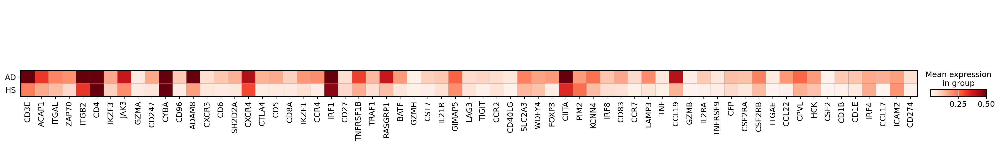

In [9]:
SHARED = ['CD3E',
 'ACAP1',
 'ITGAL',
 'ZAP70',
 'ITGB2',
 'CD4',
 'IKZF3',
 'JAK3',
 'GZMA',
 'CD247',
 'CYBA',
 'CD96',
 'ADAM8',
 'CXCR3',
 'CD6',
 'SH2D2A',
 'CXCR4',
 'CTLA4',
 'CD5',
 'CD8A',
 'IKZF1',
 'CCR4',
 'IRF1',
 'CD27',
 'TNFRSF1B',
 'TRAF1',
 'RASGRP1',
 'BATF',
 'GZMH',
 'CST7',
 'IL21R',
 'GIMAP5',
 'LAG3',
 'TIGIT',
 'CCR2',
 'CD40LG',
 'SLC2A3',
 'WDFY4',
 'FOXP3',
 'CIITA',
 'PIM2',
 'KCNN4',
 'IRF8',
 'CD83',
 'CCR7',
 'LAMP3',
 'TNF',
 'CCL19',
 'GZMB',
 'IL2RA',
 'TNFRSF9',
 'CFP',
 'CSF2RA',
 'CSF2RB',
 'ITGAE',
 'CCL22',
 'CPVL',
 'HCK',
 'CSF2',
 'CD1B',
 'CD1E',
 'IRF4',
 'CCL17',
 'ICAM2',
 'CD274']
sc.pl.matrixplot(
        adata,
        SHARED,
        groupby="disease",
        #standard_scale="var",
        dendrogram=False,
    cmap="Reds",
    vmax=.5,
    save="shared_tdc_mcp_ORIGINAL.pdf"
    )

In [10]:
adata[adata.obs.disease=="HS"].obs.sample_id.value_counts()

sample_id
output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049       36882
output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711    33391
output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049       29148
output-XETG00155__0032945__AX34-SKI-0-FO-2-S3-A2__20241217__145711    22607
output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049       14193
output-XETG00272__0021042__AX30-SKI-0-FO-2-S3__20240815__114049       13416
output-XETG00155__0032957__AX37-SKI-0-FO-2-S3-A2__20241217__145711    13306
output-XETG00155__0032945__AX34-SKI-0-FO-1-S3-A1__20241217__145711    12114
Name: count, dtype: int64

In [11]:
CMAP_BROAD = {
    'Pericyte': '#FF69B4',        # pink
    'VE': '#E41A1C',              # red
    'Fibroblast': '#FFD92F',      # yellow
    'KC_Sebocyte': '#FF8C00',     # orange
    'cDC2': '#D8B4F8',            # pale purple
    'Mast cell': '#FF5F00',       # neon orange
    'Treg': '#A8E6A3',            # pastel green
    'T': '#F5F5DC',               # beige
    'Mac': '#D2B48C',             # pastel brown
    'Plasma cell': '#8A2BE2',     # purple
    'Schwann': '#000000',         # black
    'Sweat gland': '#40E0D0',     # turquoise
    'KC_HF': '#006400',           # dark green
    'KC1-2': '#1E90FF',           # bright blue
    'Melanocyte': '#5C2E00',      # dark brown
    'LC': '#00BFFF',              # neon blue
    'cDC1': '#C8A2FF',            # lilac
    'KC3-5': '#08306B',           # dark blue
    'MigDC': '#39FF14',           # neon green
    'Smooth muscle': '#FF2E93',   # bright pink
    'NK/ILC': '#CBBE9A',          # dark beige
    'LE': '#FFFF00',              # neon yellow
    'pDC': '#D9D9D9',             # pale grey
    'Bcell': '#B3D9FF',           # pale blue
    'Adipocyte': '#FFF4A3',       # light yellow
    'T_Prolif': '#FFF0C9',        # neon beige
    'Neutrophil': '#FFD1A3'  ,     # pale orange
     'DC_other': '#EFEFFF',

}

In [12]:
adata=adata[~adata.obs["broad_annotation"].isna()]

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


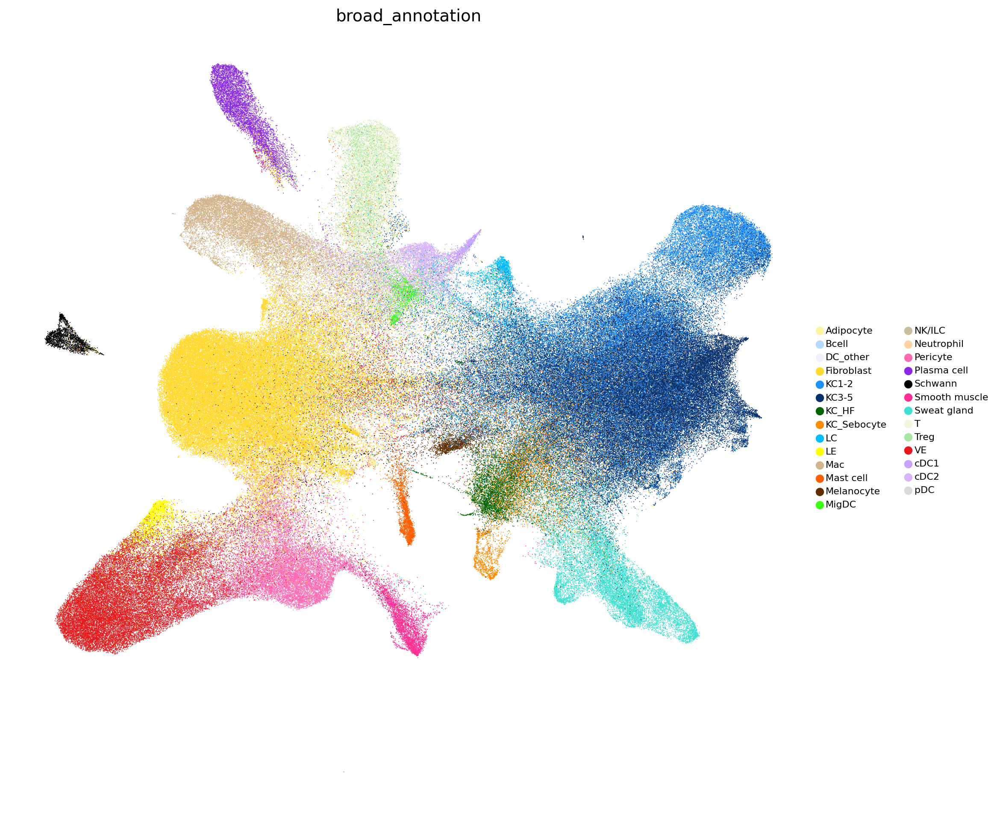

In [13]:

sc.pl.umap(adata,  
           color=[f'broad_annotation'],
           s=2,
           #legend_loc="on data",
           legend_fontoutline=2,
           legend_fontsize=8,
           save="HS_a.pdf",
           palette=CMAP_BROAD
          )



## microenvironment

In [14]:
#adata=sc.read_h5ad('/nfs/team361/ls34/inflow/adata_hs_spatial_v3_prepped3.h5ad')
#adata=sc.read_h5ad('/nfs/team361/ls34/inflow/adata_hs_spatial_prepped_V3.h5ad')
adata=sc.read_h5ad('/nfs/team361/ls34/inflow/adata_hs_spatial_v3_prepped3_V2.h5ad')

adata

AnnData object with n_obs × n_vars = 362291 × 1213
    obs: 'cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'sample_id', 'Sanger patient ID', 'Drug', 'Responder', 'Timepoint', 'Site_status', 'info_id', 'sample', 'niche_name', 'lvl1', 'lvl0', 'veryfine_celltypes_new5', 'veryfine_celltypes_new5_incprolif', 'veryfine_celltypes', 'fine_celltypes_new', 'mod_celltypes_new', 'broad_celltypes_new', 'Site_status_binary', 'fine_celltypes', 'broad_celltypes', 'broad_annotation', 'fine_annotation', 'fine_annotations', 'barcode', 'GSE', 'Patient_status', 'Location', 'Age', 'Sex', 'dataset_id', 'lvl5_annotation', 'atlas_status', 'atlas_status_reynolds', 'info_id6', 'tech', 'scanvi_predictions2', 'lvl1_new', 'Site_status_binary2', 'sample_id_dir', 'patient_id', 'n_genes_

In [15]:
adata=adata[~adata.obs["broad_annotation"].isna()].copy()

In [16]:
COLORS =   {'?Neuromuscular': '#641220',
 'Blood vessel':  '#d73435',
 'Blood vessel/perivascular': "#FFD1DC",
 'Blood vessel/perivascular2': '#FF4D6D',
 'Blood vessel2': '#8B1E3F',
 'Epidermis_basal?':  '#505aa1',
 'Epidermis_mid2':'#839edd',
 'Epidermis_outlier':  '#007AFF',
 'Mac_T_cDC2': '#009E73',
 'Neuromuscular/stroma': 'Neuromuscular/stroma',
 'Plasma-high':"#BA64FF",
 'Stroma':'#FFFFE4',
 'Stroma2':"#7f7f27",

 'Sweat gland1':  '#f4e9ef',
 'Sweat gland2':  "#7d2b56",
   "Stroma_Myofbinf":      "#00B7FF",   # NEON BLUE
    "Epidermis mid":       "#EAF4FF",   # VERY PALE BLUE
    "Sebaceous gland":     "#FF8C00",   # ORANGE
    "Perineural":          "#000000",   # BLACK
    "Sweat gland channel": "#BFEFFF",   # PALE TURQUOISE
    "Sweat gland":         "#008B8B",   # DARK TURQUOISE
    "Epidermis myofb":     "#0B1C3D",   # NAVY BLUE
    "Blood vessel myofb":  "#FF2DAA",   # NEON PINK
    "Muscle":              "#F6D6E8",   # VERY PALE PINK
    "LE":                  "#FFD700",   # BRIGHT YELLOW
    "Hypodermis":          "#E6C9A8", 
             "Perivascular2":             "#FF2DAA",  # bright pink
    "Perivascular":              "#FF0033",  # neon red
    "Pilosebaceous":             "#8D6B4E",  # orange
    "Stroma3":                   "#D4B200",  # dark yellow
    "Mast cell high":            "#FF6A00",  # neon orange
    "T_DC":                      "#39FF14",  # neon green
    "Plasma high?":              "#B026FF",  # neon purple
    "Epidermal_basal_cycling":   "#00CFFF",  # very bright sky blue
    "KC_other":                  "#0B1C3D",  # dark navy
            
            
            'Epidermis_basal': "#EAF4FF",   
            'Epidermis_mid_cycling':   "#0066FF",   # BRIGHT BLUE
 'Epidermis_basal_cycling': '#00CFFF',
            
            
            'Plasma_cell_domain': "#BA64FF",
 'Epidermis_cycling':'#0066FF', 
 'Epidermis_basal/mid':   '#00CFFF',
            
                "Epidermis_basal":     "#0066FF",   # BRIGHT BLUE

             'Epidermis_mid':   "#172B4C",
            'Epidermis_mid1': '#00CFFF',
 'Epidermis_late':'#172B4C', #b1dae6

            
            'Mast_cell_high': '#FF6A00', 
            'Plasma_cell_high': '#BA64FF'

}
            
    
{x:x for x in adata.obs["spatial_niche"].unique() if x not in COLORS.keys()}           
       

{}

In [17]:
adata[adata.obs["fine_annotation"].str.startswith("F")].obs.fine_annotation.value_counts()

fine_annotation
F7: Myofibroblast                 24227
F2: Universal                     21823
F1: Superficial                   14961
F3: FRC-like                       5746
F2/3: Perivascular                 5614
F5: RAMP1+                         2715
F6: Inflammatory myofibroblast     2110
F5: NGFR+                          1930
F4: TNN+COCH+                      1422
F4: DS_DPEP1+                      1362
F_Fascia                             52
F4: DP_HHIP+                         15
Name: count, dtype: int64

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:394: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  cax = scatter(


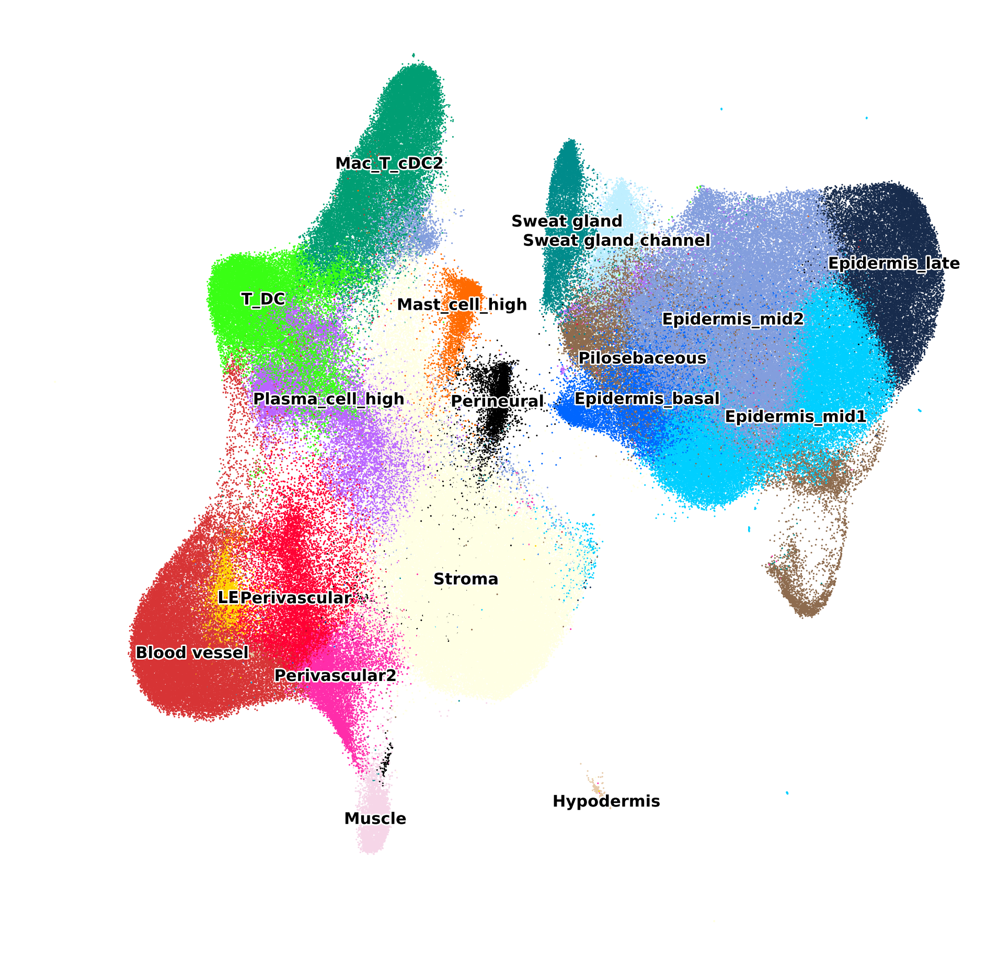

In [18]:
sc.pl.umap(adata,  
           color=["spatial_niche"],
           s=5,
           legend_loc="on data",
           legend_fontsize=11
           ,
        
          palette=COLORS,
           legend_fontoutline=2,
                      title='',

                      save="HS_SPATIAL_withlabels.pdf"

          )

# sc.pl.umap(adata,  
#            color=["spatial_niche"],
#            s=5,
#          #  legend_loc="on data",
#            legend_fontsize=20,
          
#           palette=COLORS,
#            legend_fontoutline=2,
#                       save="HS_SPATIAL_withoutlabels.pdf"

#           )





# Spatial domain composition

/tmp/ipykernel_3867790/1759178116.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["spatial_niche", "disease"])


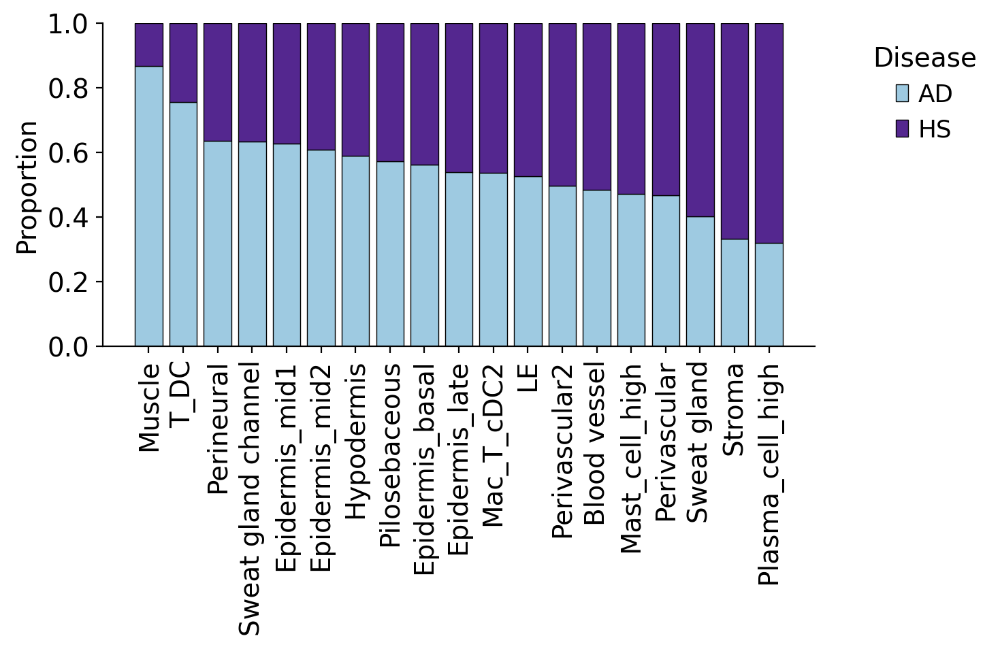

In [19]:

# --------------------------------------------------
# 1. Build contingency table
# --------------------------------------------------
df = (
    adata.obs
    .groupby(["spatial_niche", "disease"])
    .size()
    .unstack(fill_value=0)
)

# --------------------------------------------------
# 2. Convert to proportions per spatial_niche
# --------------------------------------------------
df_prop = df.div(df.sum(axis=1), axis=0)

# --------------------------------------------------
# 2.5 Sort by HS proportion
# --------------------------------------------------
df_prop = df_prop.sort_values(by="HS", ascending=True)

# --------------------------------------------------
# 3. Define pastel colors (explicit, no guessing)
# --------------------------------------------------
colors = {
    "AD": "#9ecae1",   # pastel blue
    "HS": "#54278f",   # dark purple
}

# --------------------------------------------------
# 4. Plot stacked bar chart
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(0.4 * len(df_prop), 5))

bottom = np.zeros(len(df_prop))

for disease in df_prop.columns:
    values = df_prop[disease].values
    ax.bar(
        df_prop.index,
        values,
        bottom=bottom,
        label=disease,
        color=colors.get(disease, "black"),  # fallback safety
        edgecolor="black",
        linewidth=0.5
    )
    bottom += values

# --------------------------------------------------
# 5. Cleanup
# --------------------------------------------------
ax.set_ylabel("Proportion")
ax.set_xlabel("")
ax.set_ylim(0, 1)

ax.tick_params(axis="x", rotation=90)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)

ax.legend(
    title="Disease",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    frameon=False
)

plt.tight_layout()
fig.savefig(
    "figures/b_composition_by_disease.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [20]:
# stop

# Show all HS sections + signalling scores

In [21]:
adata_hs=adata[adata.obs["disease"]=="HS"].copy()

output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711.h5ad


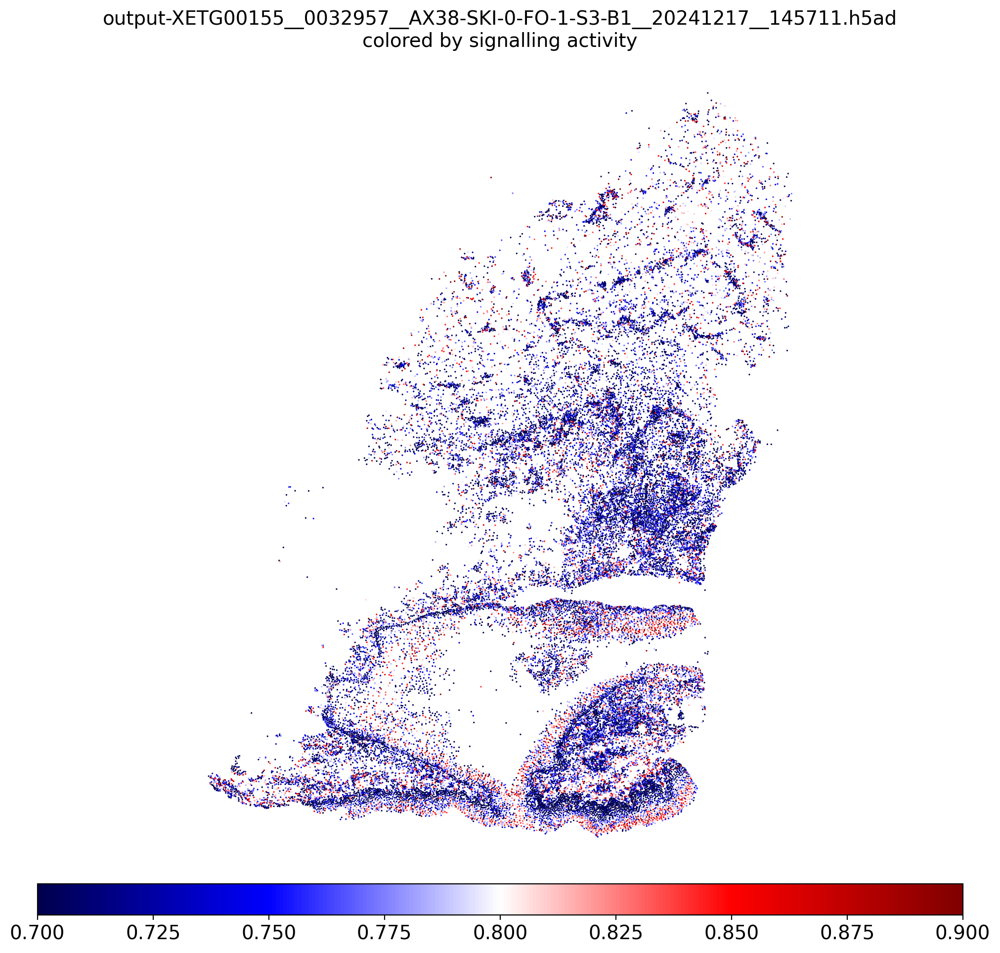

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


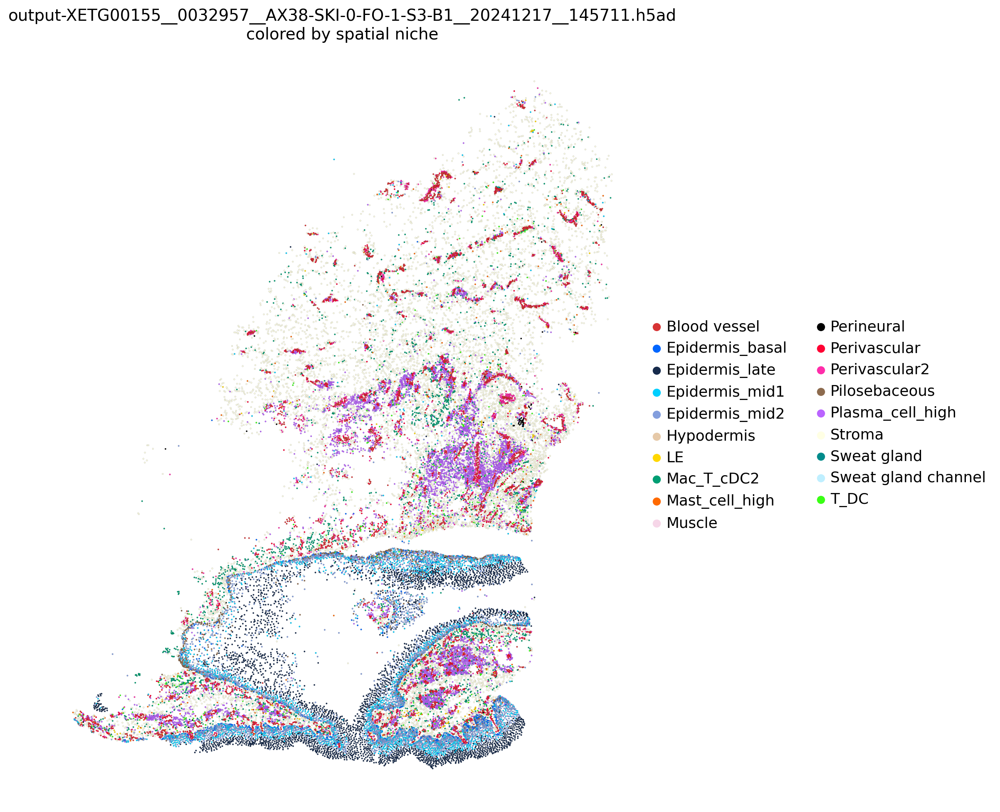

output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049.h5ad


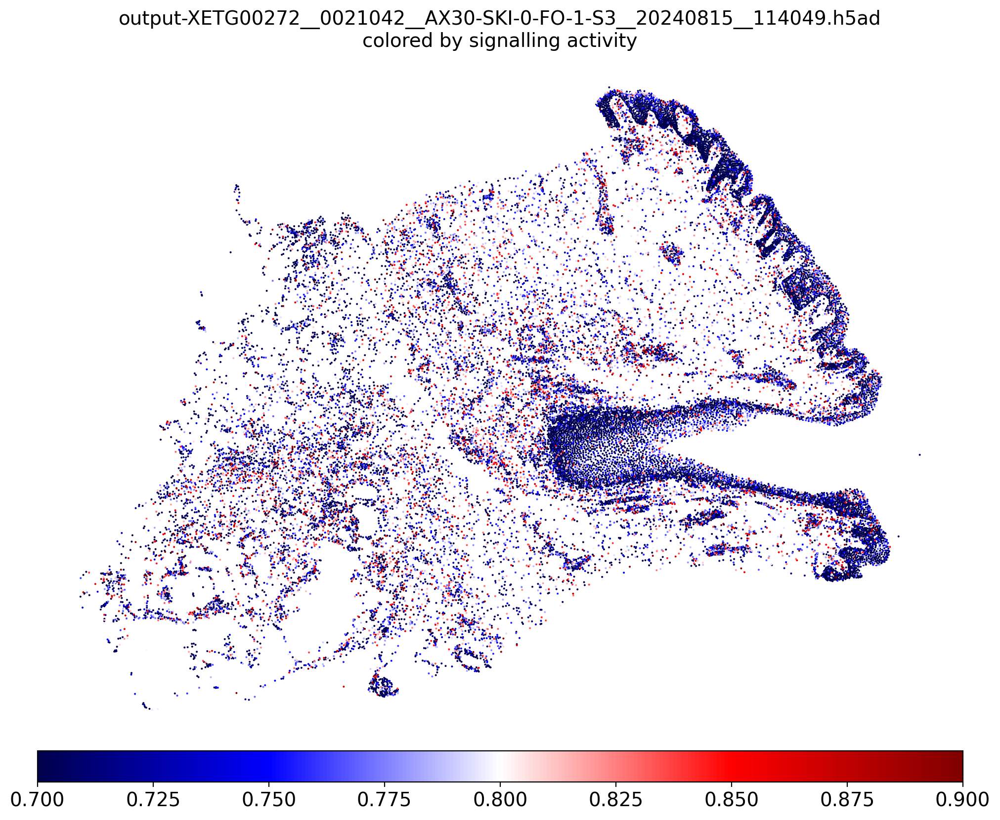

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


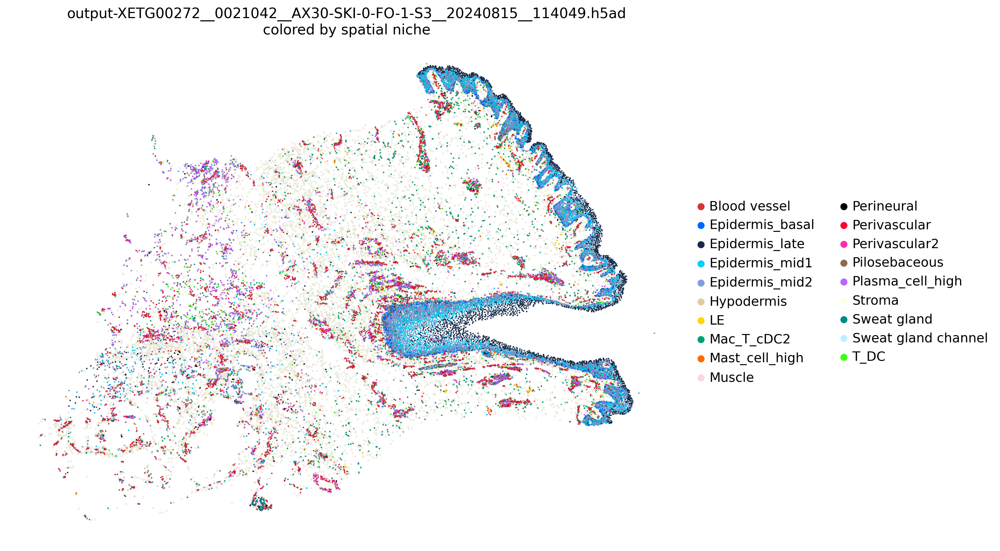

In [22]:
KEEP = [ 'output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711.h5ad',
# 'output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049',
# 'output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049',
 'output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049.h5ad']

for slice_id in KEEP:
    print(slice_id)

    sc.pl.spatial(
        adata[adata.obs['batchID_for_MintFlow'] == slice_id],
        color=['signalling_score'],
        spot_size=12.0,
        wspace=0.5,
        cmap='seismic',
        title=['{}\ncolored by signalling activity'.format(slice_id)],
        colorbar_loc='bottom',
                    vmin=0.7, vmax=.9,
                          save=f"signalling_spatial_{slice_id}.pdf"
    )
    
    
    sc.pl.spatial(
        adata[adata.obs['batchID_for_MintFlow'] == slice_id],
        color=['spatial_niche'],
        spot_size=12.0,
        wspace=0.5,
        cmap='seismic',
        title=['{}\ncolored by spatial niche'.format(slice_id)],
        colorbar_loc='bottom',
        palette=COLORS,
        linewidth=0.05,
        edgecolor='black',
                                  save=f"spatialniche_{slice_id}.pdf"

        
                          #  save="signalling_spatial.pdf"
    )

# Site status L vs NL

/tmp/ipykernel_3867790/1544657675.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["Site_status_binary", "spatial_niche"])
/tmp/ipykernel_3867790/1544657675.py:75: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


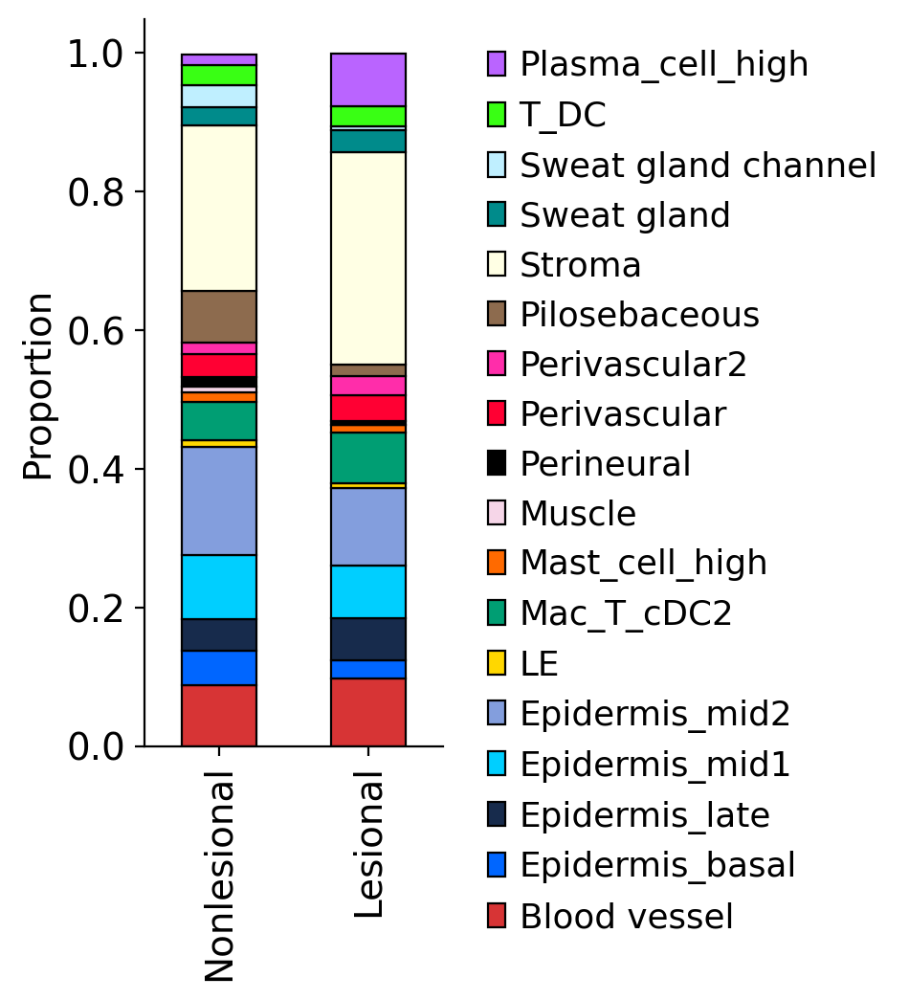

In [23]:
# --------------------------------------------------
# 1. Subset data
# --------------------------------------------------
ADATA = adata_hs[adata_hs.obs["Site_status_binary"].isin(["Lesional", "Nonlesional"])]

# --------------------------------------------------
# 2. Build normalized contingency table
# --------------------------------------------------
df = (
    ADATA.obs
    .groupby(["Site_status_binary", "spatial_niche"])
    .size()
    .unstack(fill_value=0)
)

df_norm = df.div(df.sum(axis=1), axis=0)

# drop extremely rare niches
df_norm = df_norm.loc[:, df_norm.mean() >= 0.002]

# --------------------------------------------------
# 3. Force stack order: Plasma-Mac on top
# --------------------------------------------------
cols = list(df_norm.columns)

if "Plasma_cell_high" in cols:
    cols = [c for c in cols if c != "Plasma_cell_high" ] + [ "Plasma_cell_high" ]

df_norm = df_norm[cols]
df_norm = df_norm.reindex(["Nonlesional", "Lesional"])


# --------------------------------------------------
# 4. Build color list in stack order
# --------------------------------------------------
color_list = [COLORS.get(cat, "#D3D3D3") for cat in df_norm.columns]

# --------------------------------------------------
# 5. Plot stacked bar chart
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(2, 5))

df_norm.plot(
    kind="bar",
    stacked=True,
    color=color_list,
    edgecolor="black",
    linewidth=0.8,
    ax=ax,
)

# --------------------------------------------------
# 6. Aesthetic cleanup
# --------------------------------------------------
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_title("")
ax.set_xlabel("")
ax.set_ylabel("Proportion")

# legend: top-of-bar first
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles[::-1],
    labels[::-1],
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    frameon=False,
    title=""
)

plt.xticks(rotation=90)
plt.tight_layout()
fig.savefig(
    "c_lesional_vs_nl_domains.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# T_DC composition + PC compositon

In [24]:
colors = {'Adipocyte': '#B8860B',
 'F1: Superficial': '#FFFFE4',
 'F1: Regenerative': '#FFFFE4',
 'F2/3: Perivascular': '#78b5d7',
 'F2: Universal': '#d0e1f2',
 'F3: FRC-like': '#fbd4d7',
 'F4: DS_DPEP1+': '#d3eec9',
 'F4: TNN+COCH+': '#80ca80',
 'F5: NGFR+': '#788bd2',
 'F5: RAMP1+': '#9e99c9',
 'F6: Inflammatory myofibroblast': '#00ffff',
 'KC1/2': '#505aa1',
 'KC2/3_cycling': '#007FFF',
 'KC_cycling': '#007FFF',
 'KC3': '#839edd',
 'KC4': '#b1dae6',
 'KC5': '#272c5f',
 'KC_HF: Basal': '#006400',
 'KC_HF: m': '#abe8bd',
 'KC_HF: HS': '#abe8bd',
 'KC_HF: IRS+HS': '#abe8bd',
 'KC_SebocyteGland_Outer': '#fe5e00',
 'KC_SebocyteGland_Inner': '#ffff33',
 'KC_SebocyteDuct_Outer/HF_Junction': '#5C430F',
 'KC_SebocyteDuct_Outer': '#958159',
 'KC_SebocyteDuct_Inner': '#f6d7b0',
 'KC_HF: ORS0': '#003200',
 'KC_HF: ORS1': '#9ad295',
 'KC_HF: ORS1/2': '#9ad295',
 'KC_HF: ORS2': '#e7f9e5',
 'KC_HF: IRS': '#ff083a',
 'KC_HF: IRS_cycling': '#FF849D',
 'KC: HF ORS1/2': '#94cb72',
 'KC_HF: IRS+HS_medulla': '#94cb72',
 'KC_HF: IRS_TCHH+': '#990523',
 'KC_SC: LGR6+ACTA2+': '#008080',
 'KCinflamm_basal/int': '#f4e9ef',
 'KCinflamm_late': '#D49BB1',
 'LC': '#63D7F0',
 'LC_SLC18A2+': '#3bc1d9',
 'LE': '#FFFF00',
 'Mac': '#845DAE',
 'Mac2': '#845DAE',
 'Mac2_CCL14hi': '#4F2F6D',
 'Mast cell': '#f8ac59',
 'Melanocyte': '#6f3a3a',
 'MigDC': '#00FF00',
 'MigDC (cDC2)': '#00FF00',
 'MigDC (cDC1)': '#FF9999',
 'Smooth muscle': '#f371af',
 'Nonspecific': '#D3D3D3',
 'Pericyte1': '#F7A3C3',
 'Pericyte2_VSMC': '#D04A8A',
 'Plasma cell': "#D904FF",#'#ff5e00',
 'KC_Sebocyte_basal': '#e28743',
 'KC_Sebocyte_inner': '#ffd1a3',
 'KC_Sebocyte': '#ffd1a3',
 'Sweat gland': '#00CCCC',
 'Sweat gland channel': '#2DA8A0',
 'Sweat gland channel_inner': '#FFE5B4',
 'Sweat gland channel inner': '#FFE5B4',
 'Sweat gland channel_outer': '#B3FFF0',
 'Sweat gland channel outer': '#B3FFF0',
 'Sweat gland Myoepithelial': '#f275ae',
 'T': '#F4D1A1',
 'T_Prolif': '#D4B082',
 'Tc': '#8C6A3B',
 'Tc1': '#8C6A3B',
 'Tc2': '#8C6A3B',
 'Tc_IL9R+GPR15hi': '#5a1f16',
          
 'Tnaive': '#F9F2E4',
           'Tnaive_CD8+': '#FBF6EC',
           'Tnaive_CD8': '#FBF6EC',
 'Treg': '#B2CBA4',
 'Treg_LRRC32+': '#68984c',
 'VE2': '#9f1a1a',
 'VE': '#9f1a1a',
 'VE1_Art': '#660000',
 'VE3_Ven': '#764869',
 'VE4_Cap': '#FFB6C1',
 'VE3_Ven_APLN+': '#FF073A',
 'cDC1': '#ac1d5c',
 'cDC2': '#6F478C',
 'cDC2: MMP12hi': '#eabdfb', # '#f71886',
 'mSchwann': "#1F51FF",#'#555555',
 'nmSchwann': '#999999',
 'pDC': '#D85B8C',
 'cDC2: EREG+CCR7+': '#7B8B43',
 'TransitionalDC': '#9b4ef5',
 'Bcell':  "#1E90FF",  # DodgerBlue – not already used
 'Cartilage': '#404040',
 'F4: DP_HHIP+': '#26a83f',
 'F4: HF-associated': '#26a83f',
 'F_Fascia': '#000000',
 'ILC1': '#FFFF00',
 'ILC1_NCR2+P2RX7+': '#c18bcb',
 'ILC1_NK': '#F4D03F',
 'ILC1/NK': '#F4D03F',
 'ILC2': '#0D47A1',
 'ILC2/3': '#F1C40F',
 'ILC3': '#C79A00',
 'ILC3 CCL1+PTGDS+': '#ff68b4',
            'ILC3_CCL1+PTGDS+': '#ff68b4',

 'ILC_Prolif': '#3F3100',
 'ILC_prolif': '#3F3100',
 'KC1': '#3a4e7a',
 'KC2': '#505aa1',
 'KC_HF: ORS_cycling': '#00b300',
 'KC_HF: Basal_NPNT+': '#006400',
 'KC_HF': '#006400',
 'KCinflamm_basal': '#f9f3fb',
 'KCinflamm': '#f9f3fb',
 'KCinflamm_int/late': '#e9c8dc',
 'KCinflamm_cycling': '#e0c5d2',
 'KC1-2_cycling': '#e0c5d2',
 'KCinflamm_int': '#f5d3e7',
 'LC_CCR7+': '#3bc1a4',
 'Mac1': '#6A3F9B',
 'Mac_CX3CR1+': "#EC6A6A", #'#CD5C5C',
 'Mac_TREM2+LPL+': '#D2C5E1',
 'Merkel cell': "#FF10F0", #'#2f2f2f',
 'MoDC': '#7F00A2',
 'MoDC/cDC2: MMP12+': '#7F00A2',
 'MoDC/cDC2': '#7F00A2',
 'Monocyte': '#D8A7FF',
 'Mono CD16+': '#E1C6FF',
 'NK': '#FF00FF',
 'Neutrophil': '#4D3F8C',
 'Satellite cell': '#F387C7',
 'Skeletal muscle': '#F14D8E',
 'Tc_IFNGhi': '#F5A600',
 'Tc3_IFNGhi': '#F5A600',
 'TRM_IL13+': '#1F51FF',
 'TRM_IL17+': '#E63238',
 'Tc_ZNF683+': '#D4B082',
 'Th': '#F9CA67',
 'Th_PPARGhi': '#FAE064',
 'Th_CXCR6+': '#F48B50',
 'TR1': '#E3F2DC',
 'cDC2: IL1B+': '#B78FE1',
 'cDC2_cycling': '#9272B4',
 'Eosinophil': '#FF5F00',
 'Mechanoreceptor ASIC2+': '#D3D3D3',
           'ASIC2+_Mechanoreceptor':  '#D3D3D3',
 'Tc_γδ': '#28c1d0',
      'T_γδ': "#28c1d0",

 'Tc0': '#5a1f16',
 'Th_PPARGhi_IL17': '#FFE064',
 'Tfh-like': '#d8e4e2',
 'Th2': '#b8bde3',
 'ILC3_prolif': '#503E00',
 'ILC1_prolif': '#666600',
 'ILC_SELL+CCR7+': '#FFFFCC',
            
    
         'F4: DS_DPEP1+': "#6A728B",#"#848FAE",# #"#081f5c", # "#EF99FF", #"#D600FF",# "#560066",# "#1A0033", #light red but dont loke "#FFE6F0", #'#d3eec9',
 'F4: TNN+COCH+': "#bad6ea", #"#d0e4fe", # "#F7CCFF", # reddish"#CA8080",  #"#d3eec9", #'#80ca80',
        'F4: DP_HHIP+': "#FF0000", #"#26a83f",
         "F4: HF-associated": "#26a83f",
    "Muscle":  "#FFC7E3" , #'#FFDAEC' ,# "#FFB4DA",  #'#f371af',
     'Smooth muscle': '#FFC7E3' ,# '#FFDAEC' ,#"#FFB4DA", 
    


#              "Other": '#D3D3D3'
          
                "KC_HF: IRS_Cuticle":        "#E97388",
    
        "KC_HF: HS Xenium":     "#0000FF",
    "KC_HF: HS":           "#8A0C26",
    
    
 "KC_HF: HS scRNA":      "#FF69B4",
    
    "Other":                "#F3F3F3",
    
    
   


    "KC_HF: ORS0":          "#006400",
    "KC_HF: ORS1":          "#66C266",
    "KC_HF: ORS2":        "#39FF14",   #  #"#FF69B4",
    "KC_HF: ORS_cycling":    "#267326" , #"#000000",
        "KC_HF: ORS_junction":   "#D6FFD0",  #"#8C8C8C", #    '#D7FFD0',
        "KC_HF: ORS-Bulb/infundibulum": "#0071e8" ,#like sebocyte gland#"#FF4500", # ve pale green"#F3FFF3",  #"#F3CCD7",

    
    
    "KC_HF: IRS":           "#0000FF",
    "KC_HF: IRS0":          "#FFA500",
    "KC_HF: IRS1":          "#FFD280",
   # "KC_HF: IRS2":          "#FFDDC1",      # "#008000",
    "KC_HF: IRS_cycling":   "#00F5FF",
        'KC_HF: Matrix':  "#00F5FF",

    'KC_SebocyteDuct_Outer':   "#FF69B4",
    #e6ecf0
    "KC_HF: ORS cycling(new)":   "#1A1A1A",
    "KC_HF: HFSC":               "#D600FF",
  
    
    "KC_Sebocyte_DuctOuter":                 "#000000",  # black
    "KC_Sebocyte_DuctInner":                 "#C8A165",  # light brown
    "KC_Sebocyte_GlandBasal":                "#FF6B00",  # neon orange
    "KC_Sebocyte_GlandInner":                "#FFFFCC",  # yellow
  
    "KC_SebocyteDuct_Inner":                 "#D2691E",  # “neon” brown (bright chocolate)
    "KC_SebocyteDuct_Outer/HF_Junction":     "#87CEEB",  # light blue (sky blue)
        'KC_Sebocyte_DuctInner_Junction':   "#FF69B4", 

    "KC_SebocyteGland_Outer":                "#FFA500",  # orange
    
     'Sweat gland': '#00CCCC',
 'Sweat gland channel': '#2DA8A0',
 'Sweat gland channel_inner': "#FFC680",#'#D1F9F6',
         'Sweat gland channel inner': "#FFC680",#'#D1F9F6',
# 'Sweat gland channel outer': 'Sweat gland channel outer',
 'Sweat gland channel_outer': "#99EEEE", #'#40E0D0',
        'Sweat gland channel outer': "#99EEEE",
                "Sweat gland Myoepithelial":  "#f275ae",
    
    
    
    
         'F4: DS_DPEP1+': "#6A728B",#"#848FAE",# #"#081f5c", # "#EF99FF", #"#D600FF",# "#560066",# "#1A0033", #light red but dont loke "#FFE6F0", #'#d3eec9',
 'F4: TNN+COCH+': "#bad6ea", #"#d0e4fe", # "#F7CCFF", # reddish"#CA8080",  #"#d3eec9", #'#80ca80',
        'F4: DP_HHIP+': "#FF0000", #"#26a83f",
         "F4: HF-associated": "#26a83f",
    "Muscle":  "#FFC7E3" , #'#FFDAEC' ,# "#FFB4DA",  #'#f371af',
     'Smooth muscle': '#FFC7E3' ,# '#FFDAEC' ,#"#FFB4DA", 
    
         
         'KC3-5': '#b1dae6',
          'KC1-2': '#505aa1',
          'TRM': '#E63238',
          'KC_Sebocyte_Duct':  "#C8A165", 
          'KC_Sebocyte_Gland': "#FFFFCC", 
          'KC_HF: ORS/IRS/HS':'#9ad295',
          'Schwann': '#555555',
          'Sweat gland/duct': '#00CCCC',
          'F5: Schwann-like': '#788bd2',
          'KC_HF: ORS/IRS': '#9ad295',
          'Pericyte': '#F7A3C3',
          'KC_Sebocyte_Duct/Gland':  "#FFFFCC",
          'ILC':  '#F1C40F',
      'KC': "#ADD8E6",              # pale blue
    'KC_HF_SPON2': "#007CFE",     # bright blue
             'KC_HF: SPON2+': "#007CFE", 
    'cDC': "#D8BFD8",             # pale purple (thistle)
    'Th/TRM prolif': "#A0522D",   # sienna (darkish beige/red)
    'Treg/Tnaive_prolif': "#006400",  # dark green
    'Tc_Prolif': "#D2B48C",       # tan (dark beige)
    'KC_HS: HS_TRPV1+': "#FF69B4",    # hot pink (very bright pink)
          'KC_HF: HS2': "#FF69B4", 
    'Plasma cell2': "#9D00FF",    # neon purple
    'beacon_ffpe': "#DCDCDC"  ,    # very light grey (gainsboro)
 'Tc_IL13+':  '#1F51FF',
 'Tc_IL17+':  '#E63238',
           
           'TRM_IL13+': '#1F51FF',
 'TRM_IL17+': '#E63238',
 'Tc_ZNF683+': '#D4B082',
          
            'F1: Superficial': '#ffef5a',
    'F2/3: Perivascular': '#364f99',
    'F2: Universal': '#91bae2',
    'F3: FRC-like': '#c6508f',
    'F4: DP_HHIP+': '#c9efb4',
    'F4: DS_DPEP1+': '#3d6f3b',
    'F4: TNN+COCH+': '#00f273',
    'F5: NGFR+': '#8981a7',
    'F5: RAMP1+': '#4b2657',
     'F6: Inflammatory myofibroblast': "#75fbfd",
     'F7: Myofibroblast': "#2f6565",
       'F8: Fascia-like myofibroblast':"#EFA093", #'#dd7465',
 'F_Fascia': "#0000004D",
                               }


# import pickle
# file_path = '/nfs/team298/ls34/color_for_adult_skin2.pkl'

# with open(file_path, 'wb') as file:
#     pickle.dump(colors, file)


# adata.obs['lvl5_annotation'] =adata.obs['lvl5_annotation'] .astype('category')
# adata.uns['lvl5_annotation_colors'] = [colors.get(cat, '#D3D3D3')  # Default to light grey if not found
#                                      for cat in adata.obs['lvl5_annotation'].cat.categories]


/tmp/ipykernel_3867790/3134819629.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["Site_status_binary", "broad_annotation"])
/tmp/ipykernel_3867790/3134819629.py:83: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


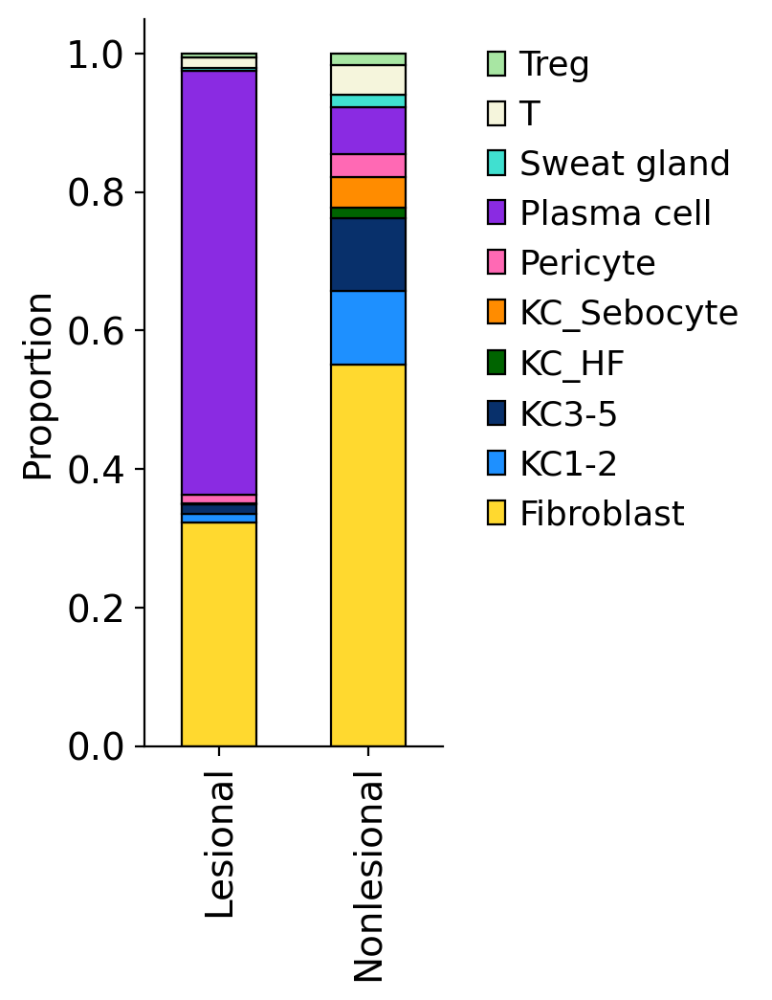

In [25]:
# --------------------------------------------------
# 1. Subset data
# --------------------------------------------------
ADATA = adata_hs[adata_hs.obs["Site_status_binary"].isin(["Lesional", "Nonlesional"])]
ADATA = ADATA[ADATA.obs["spatial_niche"] == "Plasma_cell_high"].copy()

# --------------------------------------------------
# 2. Build contingency table
# --------------------------------------------------
df = (
    ADATA.obs
    .groupby(["Site_status_binary", "broad_annotation"])
    .size()
    .unstack(fill_value=0)
)

# --------------------------------------------------
# 3. Convert to proportions
# --------------------------------------------------
df_norm = df.div(df.sum(axis=1), axis=0)

# --------------------------------------------------
# 4. Remove fine_annotation contributing <1%
# --------------------------------------------------
MIN_PROP = 0.01

keep_cols = df_norm.columns[df_norm.max(axis=0) >= MIN_PROP]

df_norm = df_norm[keep_cols]

# --------------------------------------------------
# 5. Renormalise so bars sum to 1 again
# --------------------------------------------------
df_norm = df_norm.div(df_norm.sum(axis=1), axis=0)

# --------------------------------------------------
# 6. Force row order
# --------------------------------------------------
#df_norm = df_norm.reindex(["Nonlesional", "Lesional"])

# --------------------------------------------------
# 7. Colors from dictionary
# --------------------------------------------------
color_list = [CMAP_BROAD.get(cat, "#D3D3D3") for cat in df_norm.columns]

# --------------------------------------------------
# 8. Plot stacked bars
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(2, 5))

df_norm.plot(
    kind="bar",
    stacked=True,
    color=color_list,
    edgecolor="black",
    linewidth=0.8,
    ax=ax,
)

# --------------------------------------------------
# 9. Aesthetics
# --------------------------------------------------
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_title("")
ax.set_xlabel("")
ax.set_ylabel("Proportion")

# legend order (top of stack first)
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles[::-1],
    labels[::-1],
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    frameon=False,
    title=""
)

plt.xticks(rotation=90)
plt.tight_layout()

fig.savefig(
    "figures/plasma_composition.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

/tmp/ipykernel_3867790/906874046.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["disease", "broad_annotation"])
/tmp/ipykernel_3867790/906874046.py:76: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


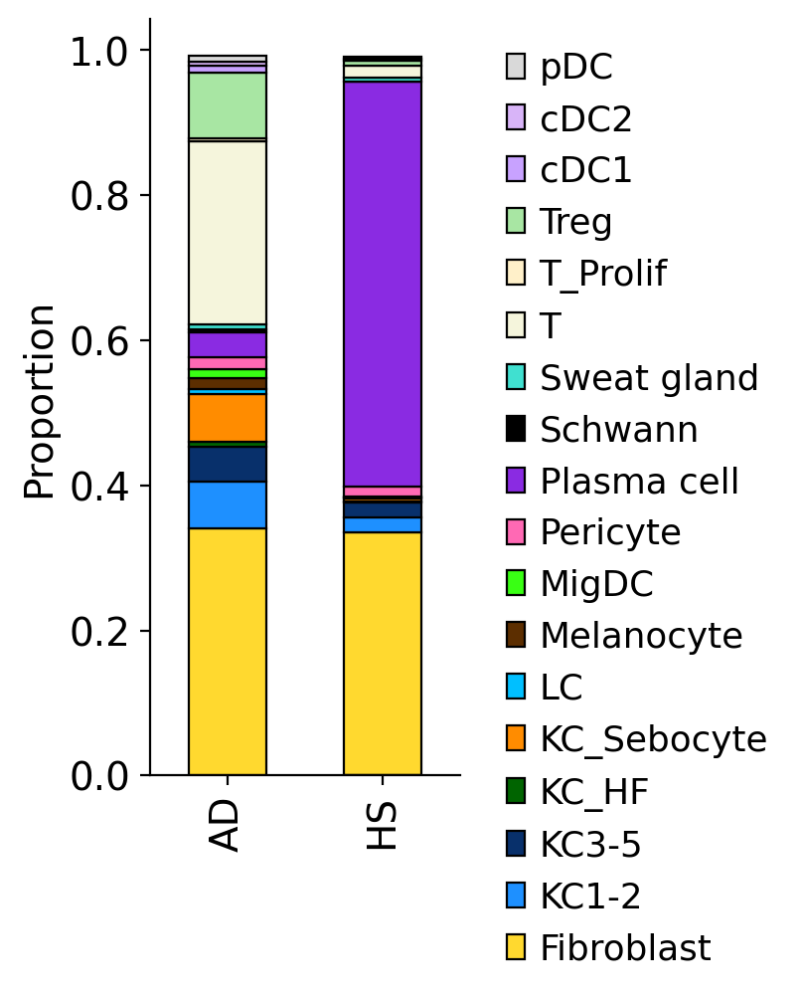

In [26]:
# --------------------------------------------------
# 1. Subset data
# --------------------------------------------------
ADATA = adata.copy()
ADATA=ADATA[ADATA.obs["spatial_niche"]=="Plasma_cell_high"].copy()
ADATA
#adata_hs[adata_hs.obs["Site_status_binary"].isin(["Lesional", "Nonlesional"])]

# --------------------------------------------------
# 2. Build normalized contingency table
# --------------------------------------------------
df = (
    ADATA.obs
    .groupby(["disease", "broad_annotation"])
    .size()
    .unstack(fill_value=0)
)

df_norm = df.div(df.sum(axis=1), axis=0)

# drop extremely rare niches
df_norm = df_norm.loc[:, df_norm.mean() >= 0.002]

# --------------------------------------------------
# 3. Force stack order: Plasma-Mac on top
# --------------------------------------------------
cols = list(df_norm.columns)

 
df_norm = df_norm[cols]
#df_norm = df_norm.reindex(["Nonlesional", "Lesional"])


# --------------------------------------------------
# 4. Build color list in stack order
# --------------------------------------------------
color_list = [CMAP_BROAD.get(cat, "#D3D3D3") for cat in df_norm.columns]

# --------------------------------------------------
# 5. Plot stacked bar chart
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(2, 5))

df_norm.plot(
    kind="bar",
    stacked=True,
    color=color_list,
    edgecolor="black",
    linewidth=0.8,
    ax=ax,
)

# --------------------------------------------------
# 6. Aesthetic cleanup
# --------------------------------------------------
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_title("")
ax.set_xlabel("")
ax.set_ylabel("Proportion")

# legend: top-of-bar first
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles[::-1],
    labels[::-1],
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    frameon=False,
    title=""
)

plt.xticks(rotation=90)
plt.tight_layout()
fig.savefig(
    "figures/plasma_bydisease_composition.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

/tmp/ipykernel_3867790/3699238487.py:14: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["disease", "broad_annotation"])
/tmp/ipykernel_3867790/3699238487.py:76: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


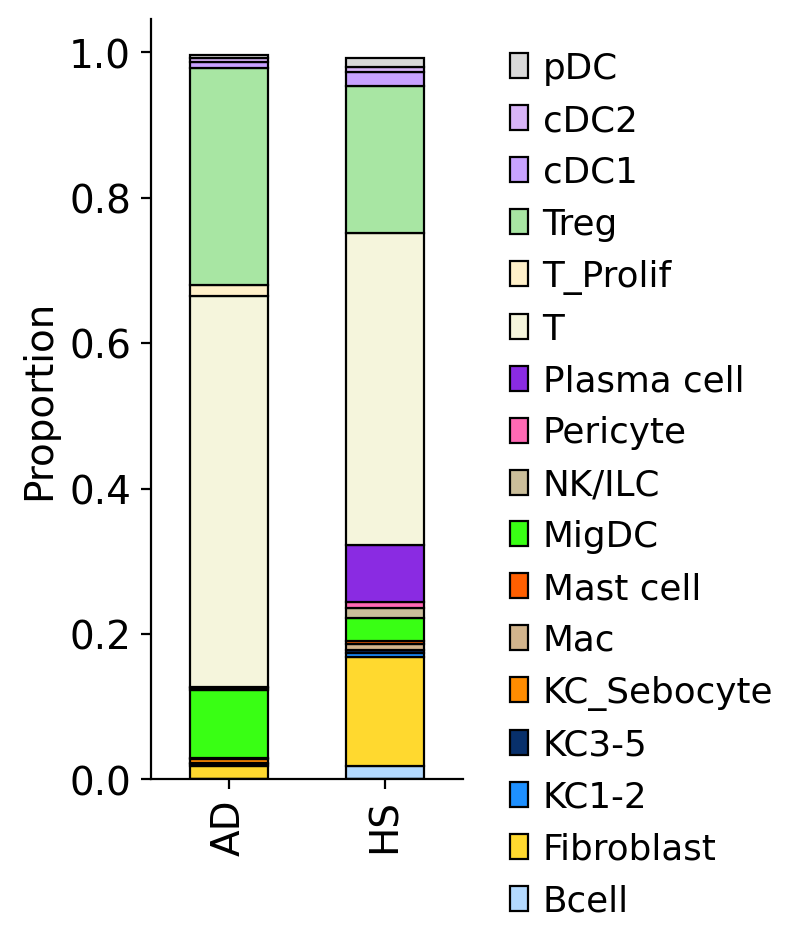

In [27]:
# --------------------------------------------------
# 1. Subset data
# --------------------------------------------------
ADATA = adata.copy()
ADATA=ADATA[ADATA.obs["spatial_niche"]=="T_DC"].copy()
ADATA
#adata_hs[adata_hs.obs["Site_status_binary"].isin(["Lesional", "Nonlesional"])]

# --------------------------------------------------
# 2. Build normalized contingency table
# --------------------------------------------------
df = (
    ADATA.obs
    .groupby(["disease", "broad_annotation"])
    .size()
    .unstack(fill_value=0)
)

df_norm = df.div(df.sum(axis=1), axis=0)

# drop extremely rare niches
df_norm = df_norm.loc[:, df_norm.mean() >= 0.002]

# --------------------------------------------------
# 3. Force stack order: Plasma-Mac on top
# --------------------------------------------------
cols = list(df_norm.columns)

 
df_norm = df_norm[cols]
#df_norm = df_norm.reindex(["Nonlesional", "Lesional"])


# --------------------------------------------------
# 4. Build color list in stack order
# --------------------------------------------------
color_list = [CMAP_BROAD.get(cat, "#D3D3D3") for cat in df_norm.columns]

# --------------------------------------------------
# 5. Plot stacked bar chart
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(2, 5))

df_norm.plot(
    kind="bar",
    stacked=True,
    color=color_list,
    edgecolor="black",
    linewidth=0.8,
    ax=ax,
)

# --------------------------------------------------
# 6. Aesthetic cleanup
# --------------------------------------------------
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_title("")
ax.set_xlabel("")
ax.set_ylabel("Proportion")

# legend: top-of-bar first
handles, labels = ax.get_legend_handles_labels()
ax.legend(
    handles[::-1],
    labels[::-1],
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    frameon=False,
    title=""
)

plt.xticks(rotation=90)
plt.tight_layout()
fig.savefig(
    "figures/t_dc_composition.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Show just T_DC + plasma cell domains

output-XETG00155__0032945__AX34-SKI-0-FO-2-S3-A2__20241217__145711.h5ad


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


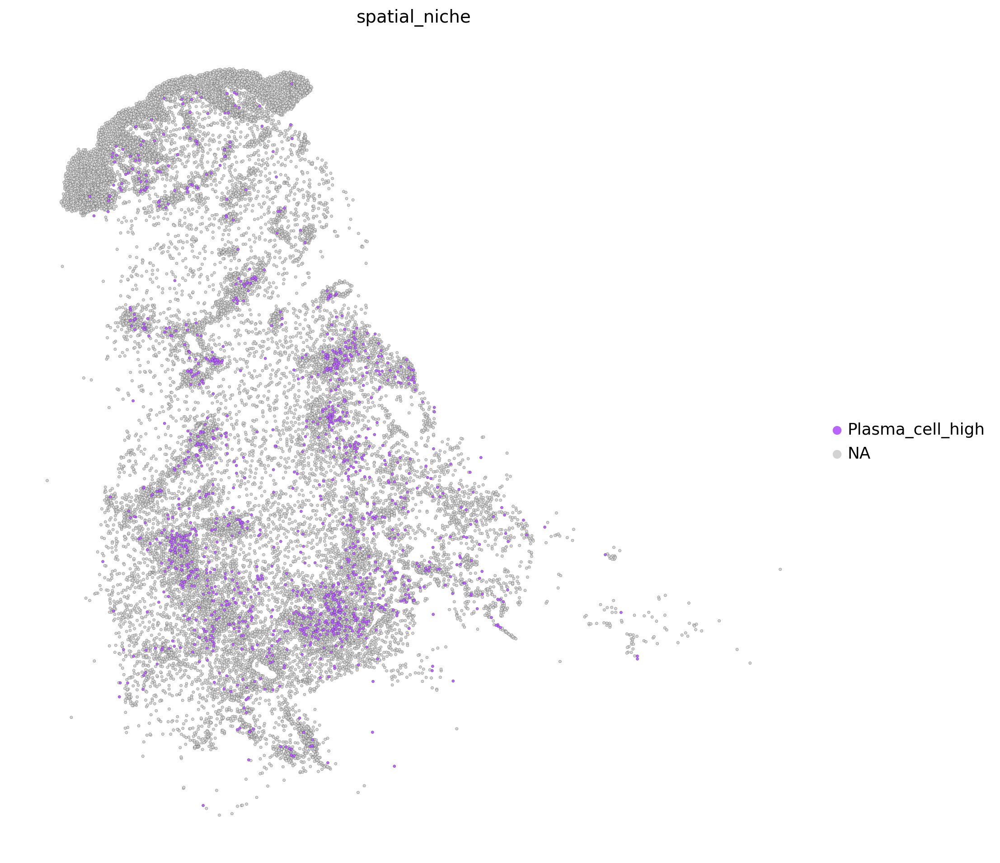

In [28]:
#for slice_id in set(adata_hs.obs['batchID_for_MintFlow']):
for slice_id in ['output-XETG00155__0032945__AX34-SKI-0-FO-2-S3-A2__20241217__145711.h5ad']:
    print(slice_id)
 
    
    sc.pl.spatial(
        adata[adata.obs['batchID_for_MintFlow'] == slice_id],
        color=['spatial_niche'],
        spot_size=20.0,
        wspace=0.5,
        cmap='seismic',
        colorbar_loc='bottom',
        palette=COLORS,
        linewidth=0.1,
        edgecolor='black',
        groups=["Plasma_cell_high"],
        save="plasmacell_dist.pdf"
        
                          #  save="signalling_spatial.pdf"
    )

output-XETG00155__0032945__AX34-SKI-0-FO-2-S3-A2__20241217__145711.h5ad


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


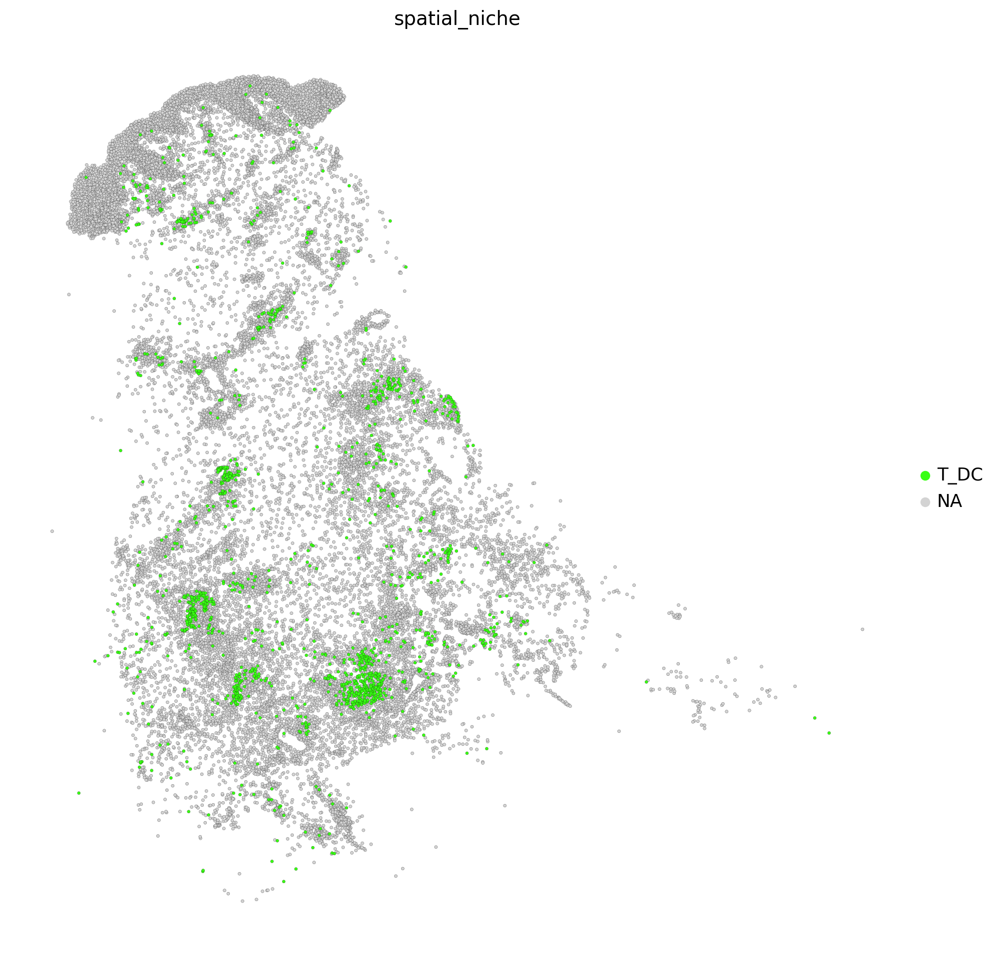

In [29]:
#for slice_id in set(adata_hs.obs['batchID_for_MintFlow']):
for slice_id in ['output-XETG00155__0032945__AX34-SKI-0-FO-2-S3-A2__20241217__145711.h5ad']:

    print(slice_id)
 
    
#     sc.pl.spatial(
#         adata[adata.obs['batchID_for_MintFlow'] == slice_id],
#         color=['spatial_niche'],
#         spot_size=20.0,
#         wspace=0.5,
#         cmap='seismic',
#         colorbar_loc='bottom',
#         palette=COLORS,
#         linewidth=0.1,
#         edgecolor='black',
#         groups=["T_DC"],
        
#                           #  save="signalling_spatial.pdf"
#     )
    sc.pl.spatial(
        adata[adata.obs['batchID_for_MintFlow'] == slice_id],
        color=['spatial_niche'],
        spot_size=20.0,
        wspace=0.5,
        cmap='seismic',
        colorbar_loc='bottom',
        palette=COLORS,
        linewidth=0.1,
        edgecolor='black',
        groups=["T_DC"],
        save="tdc_dist.pdf"
        
                          #  save="signalling_spatial.pdf"
    )

In [30]:
# #for slice_id in set(adata_hs.obs['batchID_for_MintFlow']):
# for slice_id in adata.obs['batchID_for_MintFlow'].unique():
#     if slice_id != 'output-XETG00155__0032945__AX34-SKI-0-FO-2-S3-A2__20241217__145711.h5ad':
#         print(slice_id)
 
    
# #     sc.pl.spatial(
# #         adata[adata.obs['batchID_for_MintFlow'] == slice_id],
# #         color=['spatial_niche'],
# #         spot_size=20.0,
# #         wspace=0.5,
# #         cmap='seismic',
# #         colorbar_loc='bottom',
# #         palette=COLORS,
# #         linewidth=0.1,
# #         edgecolor='black',
# #         groups=["T_DC"],
        
# #                           #  save="signalling_spatial.pdf"
# #     )
#         sc.pl.spatial(
#             adata[adata.obs['batchID_for_MintFlow'] == slice_id],
#             color=['spatial_niche'],
#             spot_size=20.0,
#             wspace=0.5,
#             cmap='seismic',
#             colorbar_loc='bottom',
#             palette=COLORS,
#             linewidth=0.1,
#             edgecolor='black',
#             groups=["T_DC"],
#             #save="tdc_dist.pdf"

#                               #  save="signalling_spatial.pdf"
#         )
#         sc.pl.spatial(
#             adata[adata.obs['batchID_for_MintFlow'] == slice_id],
#             color=['spatial_niche'],
#             spot_size=20.0,
#             wspace=0.5,
#             cmap='seismic',
#             colorbar_loc='bottom',
#             palette=COLORS,
#             linewidth=0.1,
#             edgecolor='black',
#             groups=["Plasma_cell_high"],
#           #  save="plasmacell_dist.pdf"

#                               #  save="signalling_spatial.pdf"
#         )

# Show fine cell types

output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


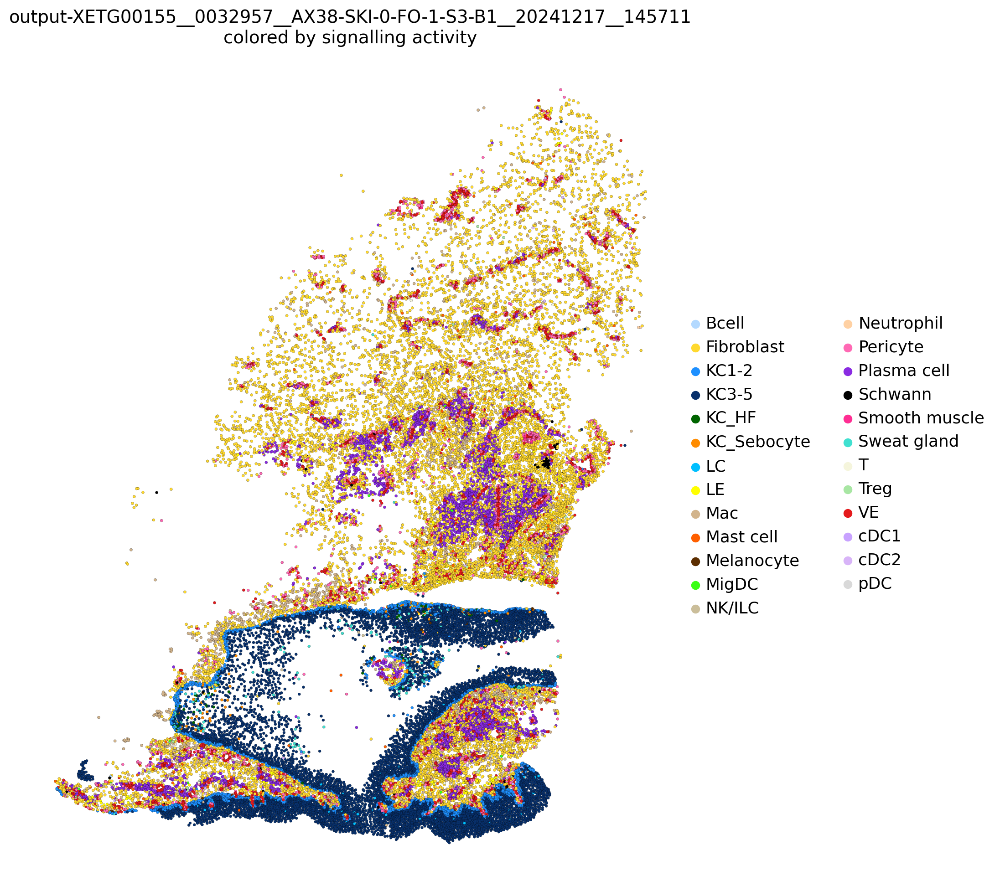

output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


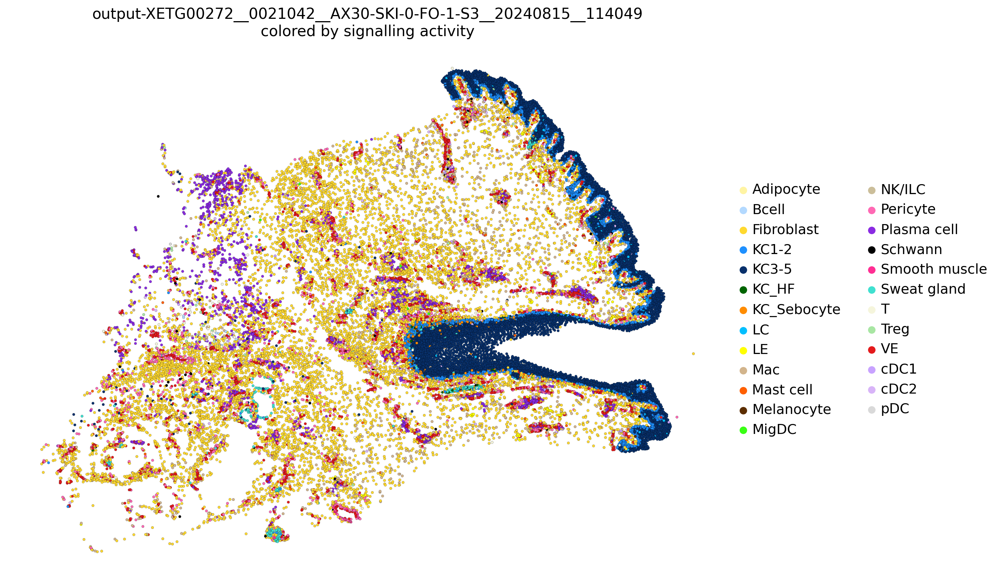

output-XETG00155__0032957__AX37-SKI-0-FO-2-S3-A2__20241217__145711


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


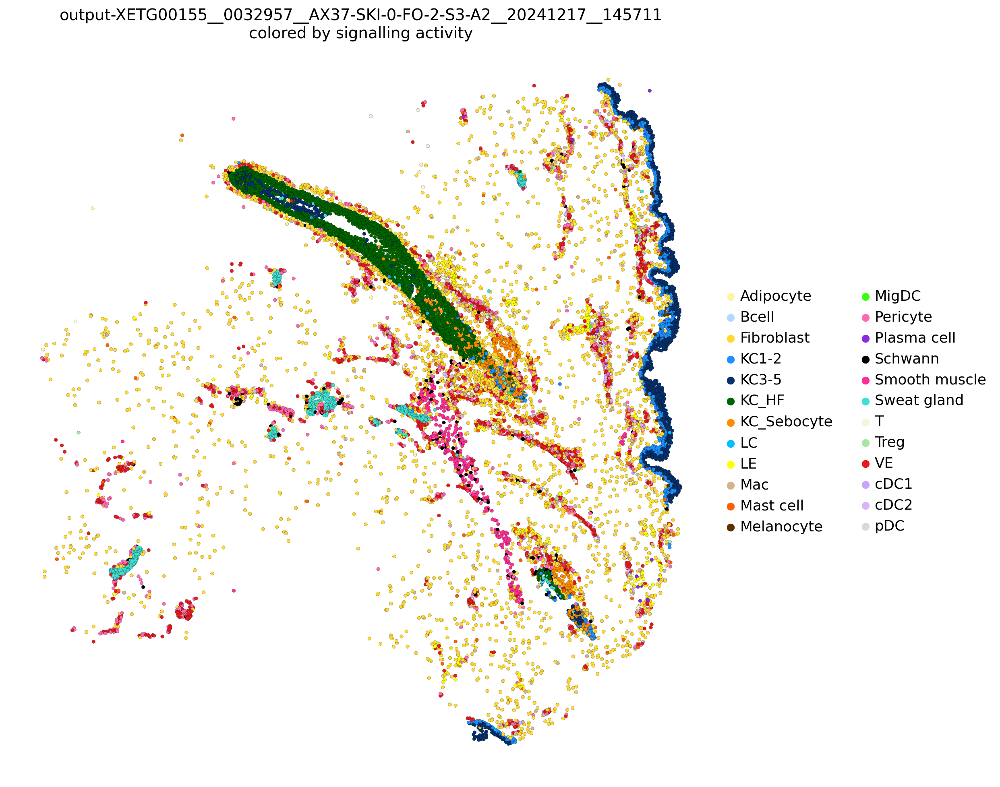

output-XETG00272__0021042__AX30-SKI-0-FO-2-S3__20240815__114049


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


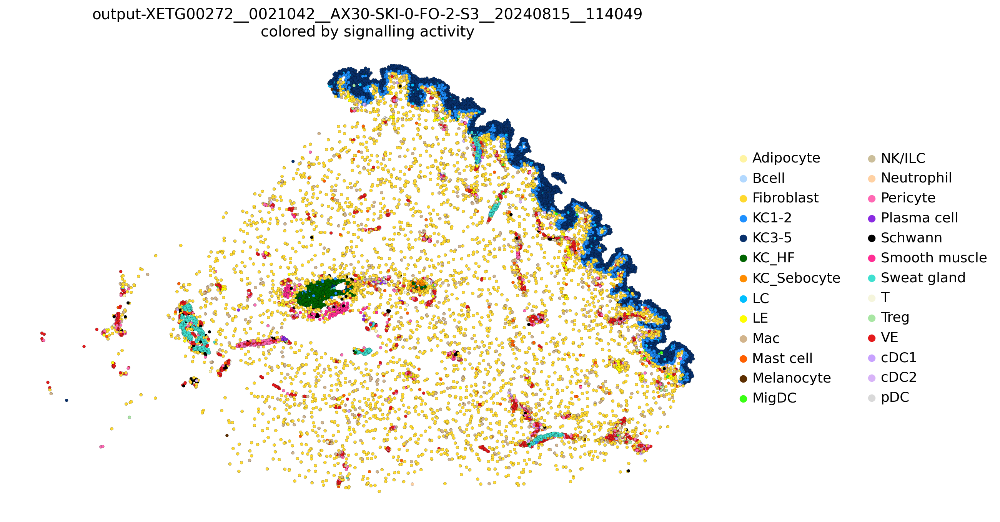

In [31]:
KEEP = [ 'output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711',
# 'output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049',
# 'output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049',
 'output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049',
        'output-XETG00155__0032957__AX37-SKI-0-FO-2-S3-A2__20241217__145711',
         'output-XETG00272__0021042__AX30-SKI-0-FO-2-S3__20240815__114049',


       ]


for slice_id in KEEP:
    print(slice_id)
    sc.pl.spatial(
        adata[adata.obs['sample_id'] == slice_id],
        color=['broad_annotation'],
        spot_size=20.0,
        wspace=0.5,
        title=['{}\ncolored by signalling activity'.format(slice_id)],
        colorbar_loc='bottom',
      #  palette=colors,
        linewidth=0.1,
        edgecolor='black',
        palette=CMAP_BROAD,

                         save=f"broad_annos_for-keyslides_{slice_id}.pdf"
    )

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


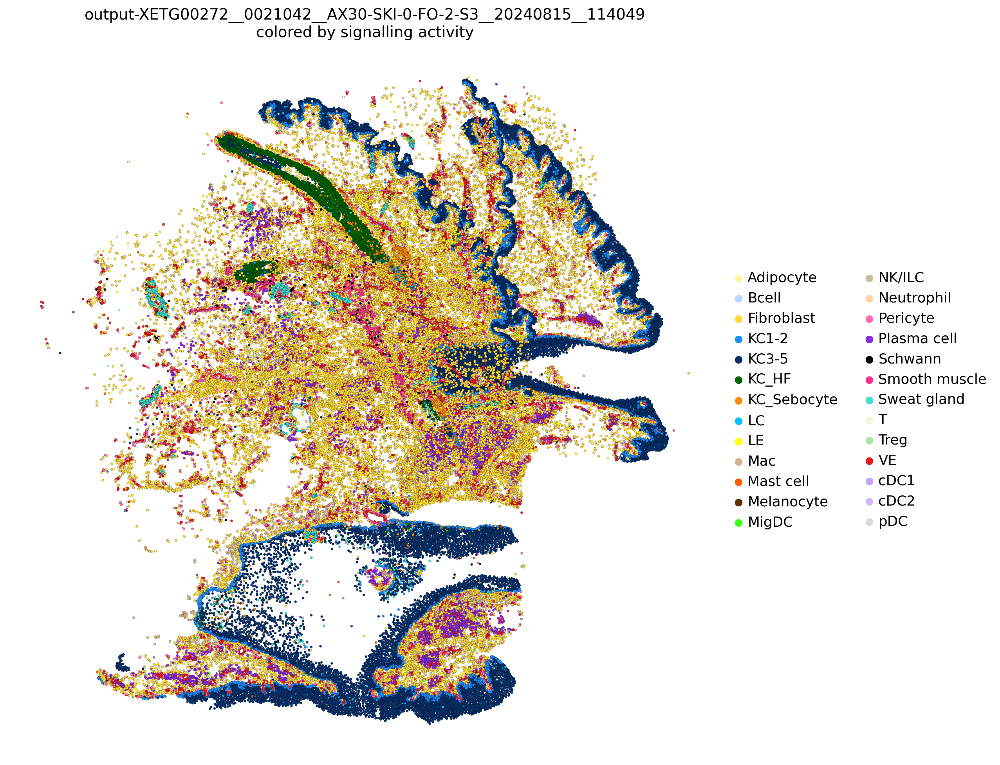

In [32]:
# KEEP = [ 'output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711',
# # 'output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049',
# # 'output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049',
#  'output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049',
       
#        ]
KEEP = [ 'output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711',
# 'output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049',
# 'output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049',
 'output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049',
        'output-XETG00155__0032957__AX37-SKI-0-FO-2-S3-A2__20241217__145711',
         'output-XETG00272__0021042__AX30-SKI-0-FO-2-S3__20240815__114049',


       ]

sc.pl.spatial(
    adata[adata.obs['sample_id'].isin(KEEP)],
    color=['broad_annotation'],
    spot_size=20.0,
    wspace=0.5,
    title=['{}\ncolored by signalling activity'.format(slice_id)],
    colorbar_loc='bottom',
  #  palette=colors,
    linewidth=0.1,
    edgecolor='black',
    palette=CMAP_BROAD,

                     save=f"broad_annos_for-keyslidesLEGEND.pdf"
)

output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


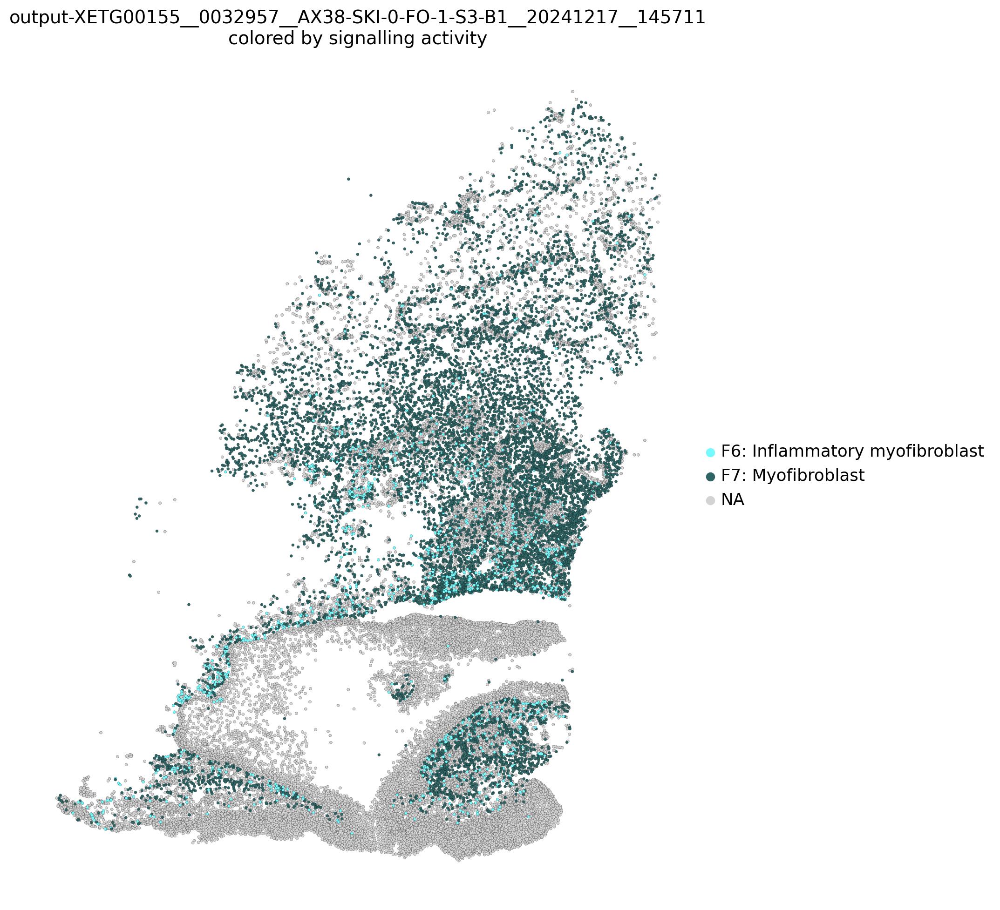

output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


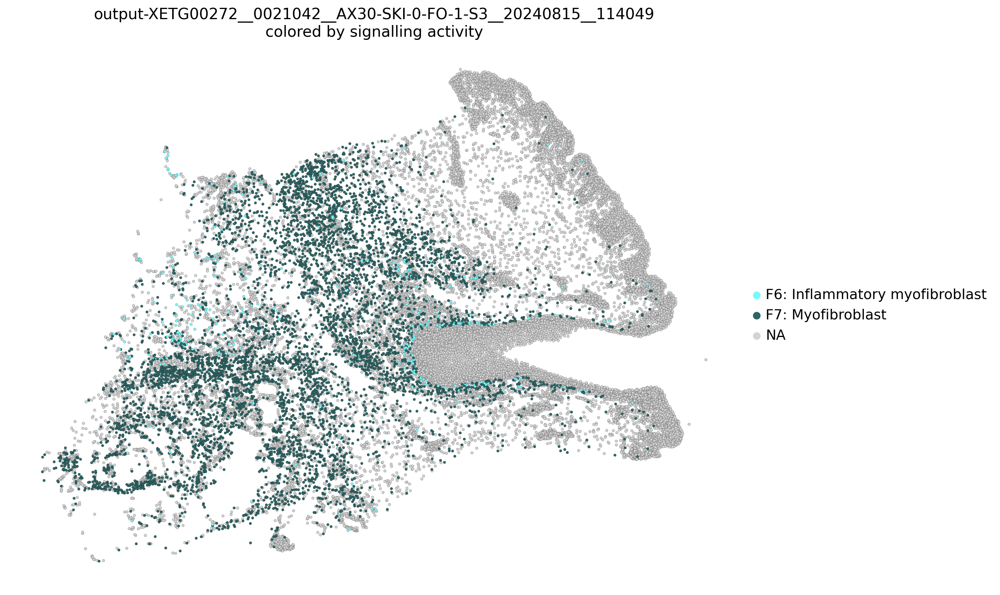

In [33]:
KEEP = [ 'output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711',
# 'output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049',
# 'output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049',
 'output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049']

# KEEP = [ 'output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711',
# # 'output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049',
# # 'output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049',
#  'output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049',
#         'output-XETG00155__0032957__AX37-SKI-0-FO-2-S3-A2__20241217__145711',
#          'output-XETG00272__0021042__AX30-SKI-0-FO-2-S3__20240815__114049',


#        ]


for slice_id in KEEP:
    print(slice_id)
    sc.pl.spatial(
        adata[adata.obs['sample_id'] == slice_id],
        color=['fine_annotation'],
        spot_size=20.0,
        wspace=0.5,
        title=['{}\ncolored by signalling activity'.format(slice_id)],
        colorbar_loc='bottom',
        palette=colors,
        linewidth=0.1,
        edgecolor='black',
        groups=["F7: Myofibroblast", "F6: Inflammatory myofibroblast"],
        
                        save=f"f6_f7_tunnels_{slice_id}.pdf"
    )

output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


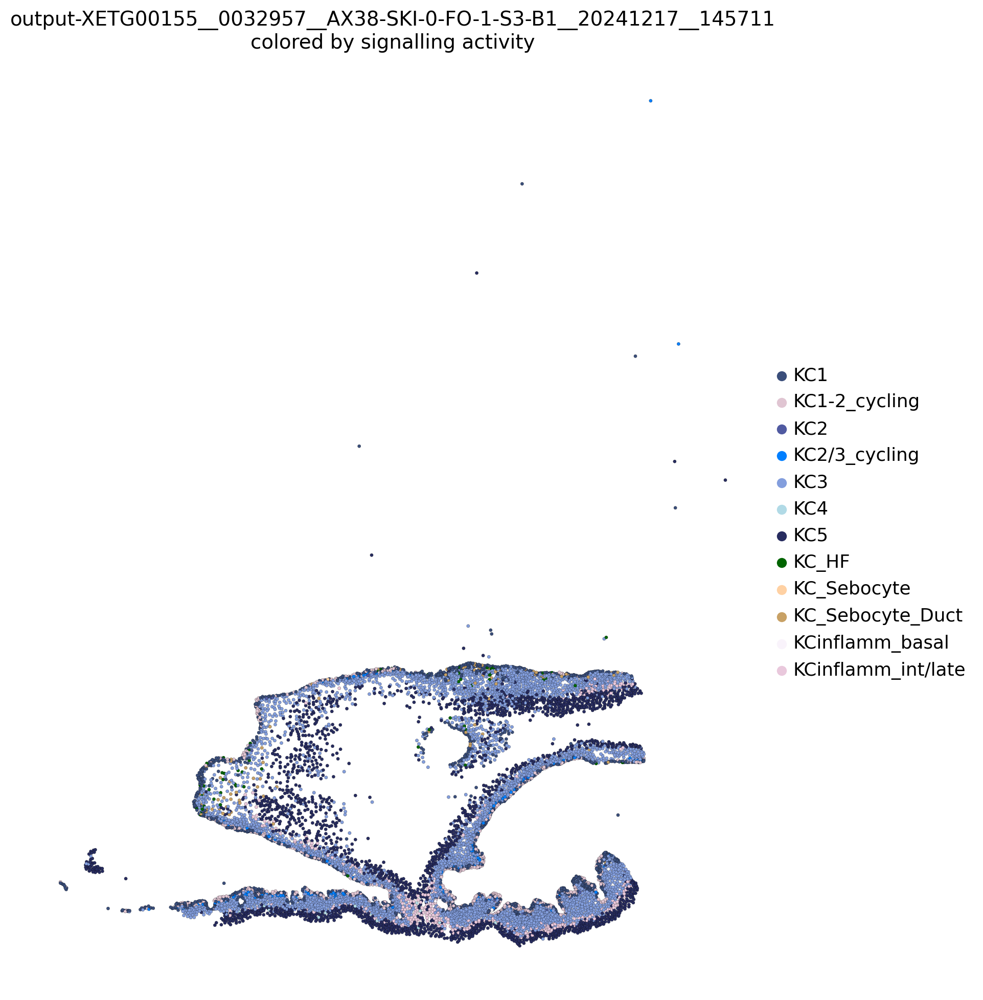

output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


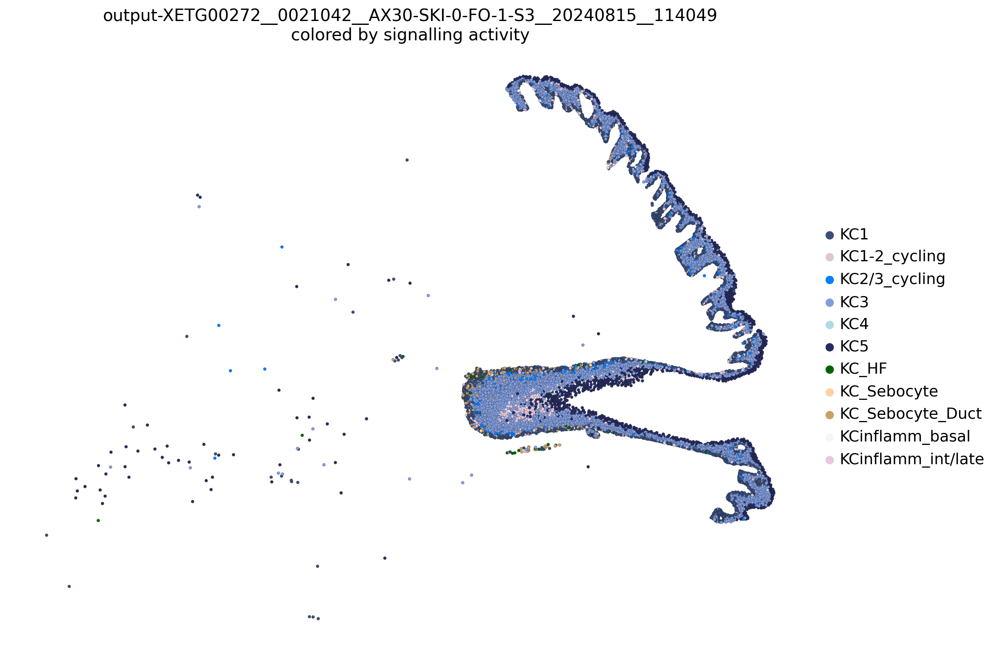

output-XETG00155__0032957__AX37-SKI-0-FO-2-S3-A2__20241217__145711


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


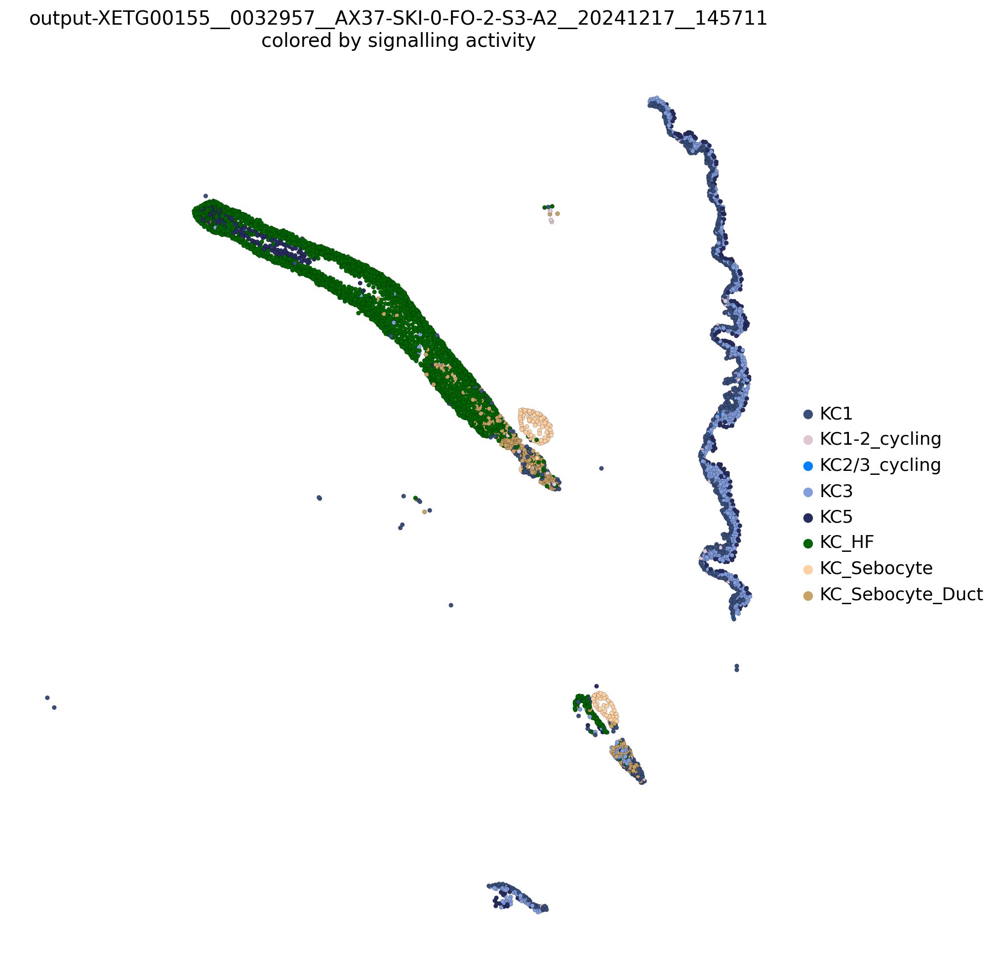

output-XETG00272__0021042__AX30-SKI-0-FO-2-S3__20240815__114049


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


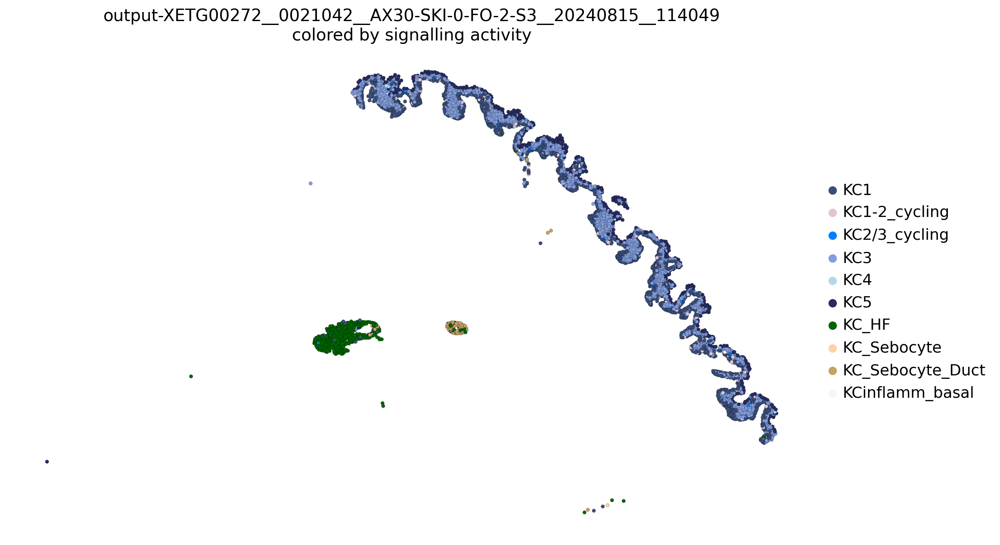

In [34]:
KEEP = [ 'output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711',
# 'output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049',
# 'output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049',
 'output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049',
        'output-XETG00155__0032957__AX37-SKI-0-FO-2-S3-A2__20241217__145711',
         'output-XETG00272__0021042__AX30-SKI-0-FO-2-S3__20240815__114049',


       ]

for slice_id in KEEP:
    print(slice_id)
    adata_i=adata[adata.obs['sample_id'] == slice_id]
    sc.pl.spatial(
        adata_i[adata_i.obs["fine_annotation"].str.startswith("KC")],
        color=['fine_annotation'],
        spot_size=20.0,
        wspace=0.5,
        title=['{}\ncolored by signalling activity'.format(slice_id)],
        colorbar_loc='bottom',
        palette=colors,
        linewidth=0.1,
        edgecolor='black',
        
                          #  save="signalling_spatial.pdf"
    )

output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


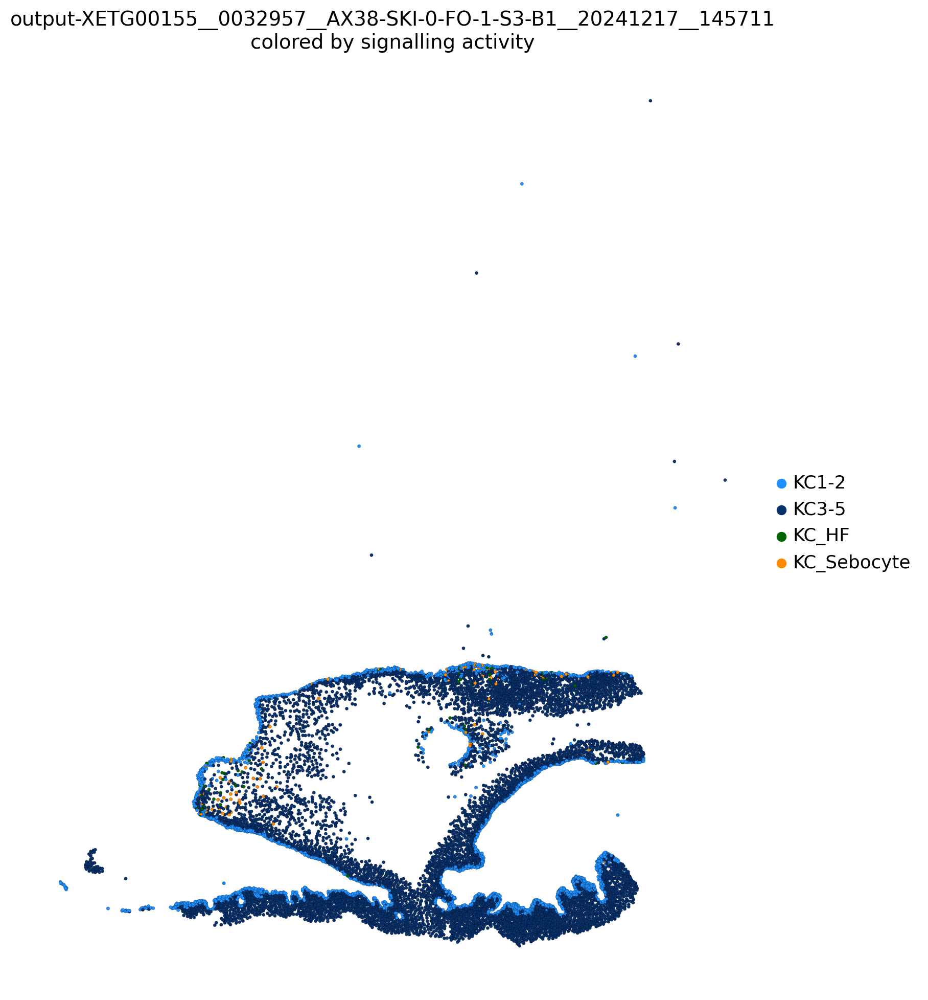

output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


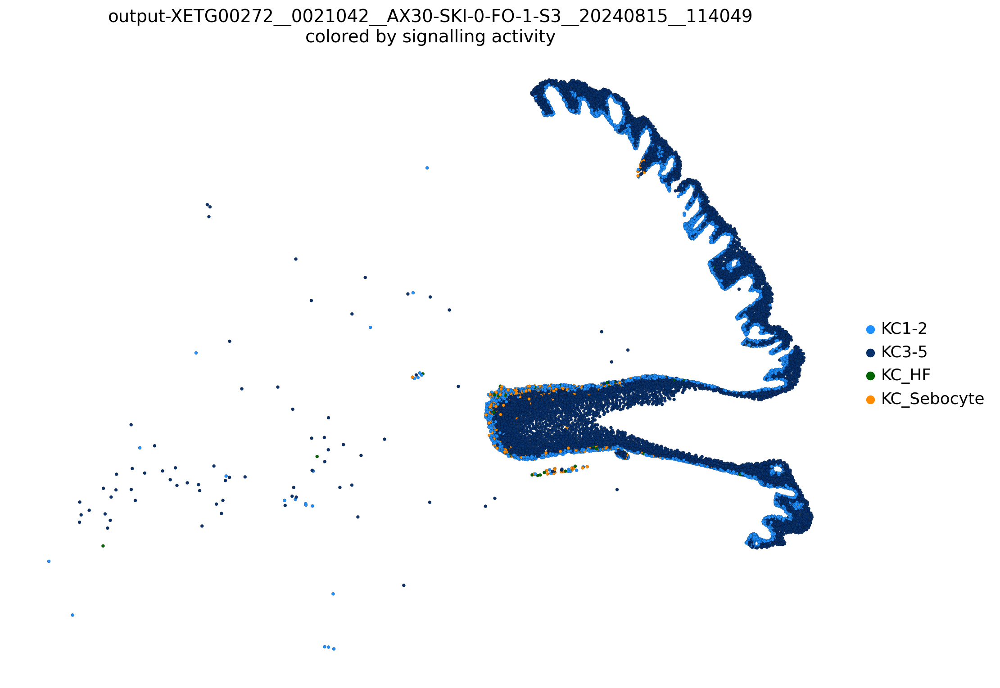

output-XETG00155__0032957__AX37-SKI-0-FO-2-S3-A2__20241217__145711


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


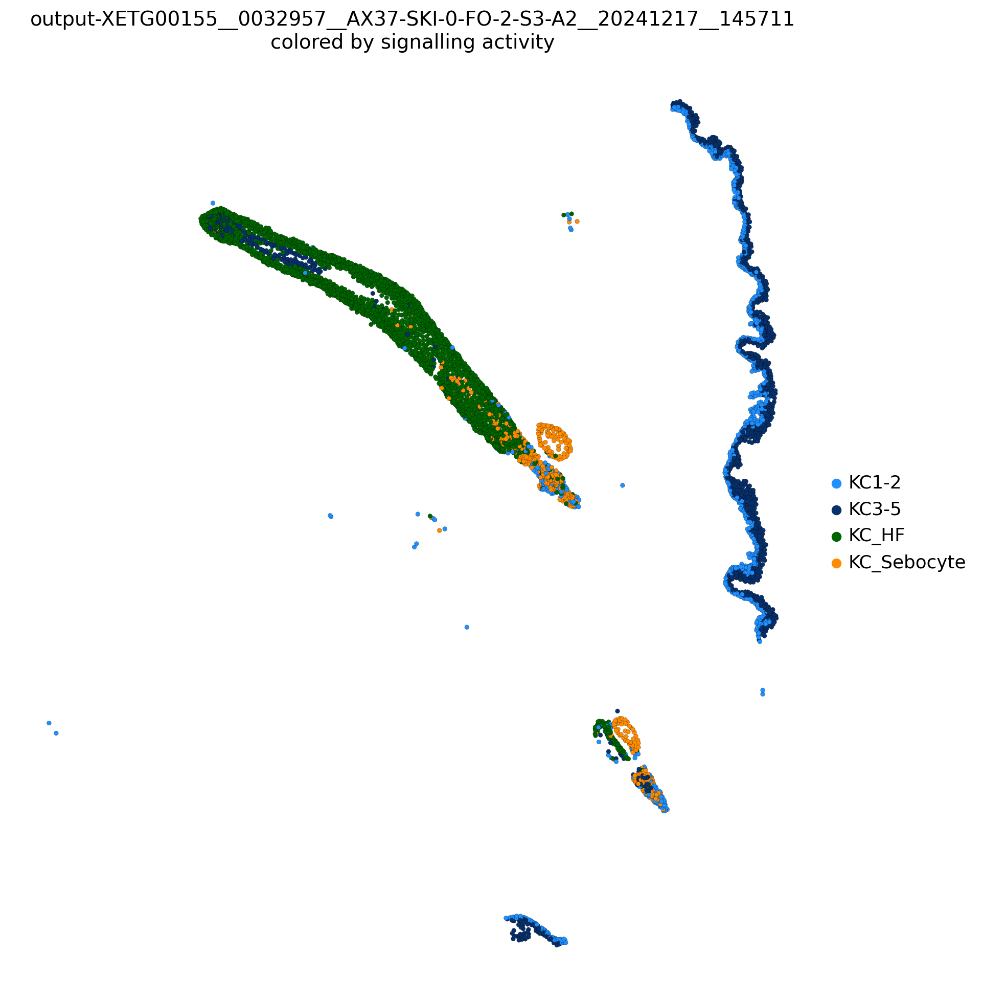

output-XETG00272__0021042__AX30-SKI-0-FO-2-S3__20240815__114049


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_utils.py:432: ImplicitModificationWarning: Trying to modify attribute `._uns` of view, initializing view as actual.
  adata.uns[value_to_plot + '_colors'] = colors_list
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


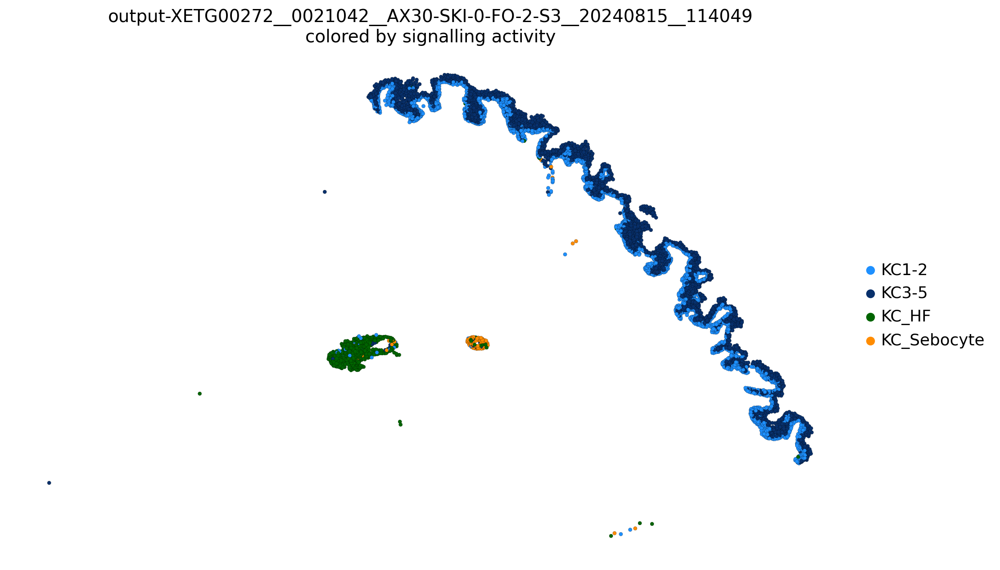

In [35]:
KEEP = [ 'output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711',
# 'output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049',
# 'output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049',
 'output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049',
        'output-XETG00155__0032957__AX37-SKI-0-FO-2-S3-A2__20241217__145711',
         'output-XETG00272__0021042__AX30-SKI-0-FO-2-S3__20240815__114049',


       ]

for slice_id in KEEP:
    print(slice_id)
    adata_i=adata[adata.obs['sample_id'] == slice_id]
    sc.pl.spatial(
        adata_i[adata_i.obs["fine_annotation"].str.startswith("KC")],
        color=['broad_annotation'],
        spot_size=20.0,
        wspace=0.5,
        title=['{}\ncolored by signalling activity'.format(slice_id)],
        colorbar_loc='bottom',
        palette=CMAP_BROAD,
        linewidth=0.1,
        edgecolor='black',
        
                          #  save="signalling_spatial.pdf"
    )

In [36]:
# KEEP = [ 'output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711',
# # 'output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049',
# # 'output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049',
#  'output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049',
#         'output-XETG00155__0032957__AX37-SKI-0-FO-2-S3-A2__20241217__145711',
#          'output-XETG00272__0021042__AX30-SKI-0-FO-2-S3__20240815__114049',


#        ]

# for slice_id in KEEP:
#     print(slice_id)
#     adata_i=adata[adata.obs['sample_id'] == slice_id]
#     sc.pl.spatial(
#         adata_i[adata_i.obs["fine_annotation"].str.startswith("KC")],
#         color=['broad_annotation'],
#         spot_size=20.0,
#         wspace=0.5,
#         colorbar_loc='bottom',
#         #palette=colors,
#         linewidth=0.1,
#         edgecolor='black',
        
#                           #  save="signalling_spatial.pdf"
#     )

In [37]:
# for slice_id in set(adata_hs.obs['batchID_for_MintFlow']):
#     print(slice_id)
 
    
#     sc.pl.spatial(
#         adata[adata.obs['batchID_for_MintFlow'] == slice_id],
#         color=['fine_annotation'],
#         spot_size=20.0,
#         wspace=0.5,
#         title=['{}\ncolored by s§ignalling activity'.format(slice_id)],
#         colorbar_loc='bottom',
#         palette=colors,
#         linewidth=0.1,
#         edgecolor='black',
#         groups=['nmSchwann', 'mSchwann', 'Schwann'],
        
#                           #  save="signalling_spatial.pdf"
#     )

In [38]:
# shared programmes

In [39]:
adata.obs.disease.value_counts()


disease
AD    186732
HS    175036
Name: count, dtype: int64

In [40]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:196: UserWarning: Some cells have zero counts
  warn(UserWarning('Some cells have zero counts'))


T_DC


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_matrixplot.py:143: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  values_df = self.obs_tidy.groupby(level=0).mean()


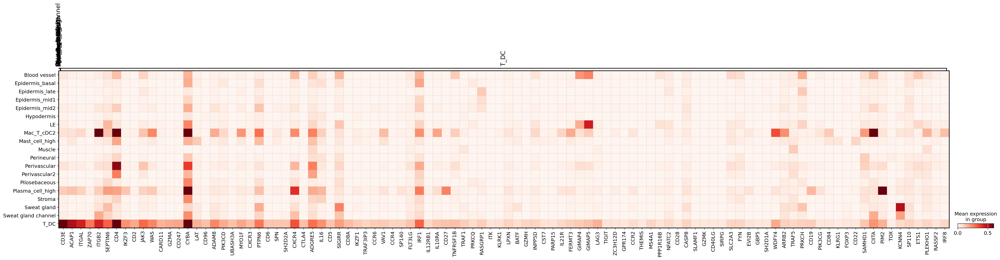

In [41]:
ADATA=adata_hs[adata_hs.obs["Site_status_binary"]=="Lesional"].copy()
#ADATA.X = ADATA.obsm["MintFlow_Xmic"].copy()
CATEGORY="spatial_niche"

sc.tl.rank_genes_groups(ADATA, CATEGORY, method='t-test', key_added="de_leiden");
df2 = pd.DataFrame(ADATA.uns['de_leiden']['names'])
df2.head(5)

RESULT_DI = {}
for i,select_population in enumerate(list(df2.columns)):
    RESULT_DI[select_population] = []
    
i=-1
select_population = list(df2.columns)[i
                                     ]
print(select_population)

genes0 = df2[select_population][:100]
genes200_TDC = df2[select_population][:200]

RESULT_DI[select_population] = genes0
genes1 = df2[select_population][50:100]
genes2 = df2[select_population][100:150]
genes3 = df2[select_population][150:200]
genes4 = df2[select_population][200:250]
genes5 = df2[select_population][250:300]
genes6 = df2[select_population][300:350]
genes7 = df2[select_population][350:400]
genes8 = df2[select_population][400:450]
sc.pl.matrixplot(
        ADATA,
        RESULT_DI,
        groupby=CATEGORY,
        #standard_scale="var",
        dendrogram=False,
    cmap="Reds",
    vmax=.6
    #save="eczema_mcps.pdf"
    )



In [42]:
import pickle

with open('eczema_tdc_mcp_top200.pkl', 'rb') as f:
    gene_programme200 = pickle.load(f)



SHARED = [x for x in  list(genes200_TDC)  if x in gene_programme200]
print(len(SHARED))
SHARED
HS_ONLY = [x for x in list(genes200_TDC)  if x not in gene_programme200]

SHARED




65


['CD3E',
 'ACAP1',
 'ITGAL',
 'ZAP70',
 'ITGB2',
 'CD4',
 'IKZF3',
 'JAK3',
 'GZMA',
 'CD247',
 'CYBA',
 'CD96',
 'ADAM8',
 'CXCR3',
 'CD6',
 'SH2D2A',
 'CXCR4',
 'CTLA4',
 'CD5',
 'CD8A',
 'IKZF1',
 'CCR4',
 'IRF1',
 'CD27',
 'TNFRSF1B',
 'TRAF1',
 'RASGRP1',
 'BATF',
 'GZMH',
 'CST7',
 'IL21R',
 'GIMAP5',
 'LAG3',
 'TIGIT',
 'CCR2',
 'CD40LG',
 'SLC2A3',
 'WDFY4',
 'FOXP3',
 'CIITA',
 'PIM2',
 'KCNN4',
 'IRF8',
 'CD83',
 'CCR7',
 'LAMP3',
 'TNF',
 'CCL19',
 'GZMB',
 'IL2RA',
 'TNFRSF9',
 'CFP',
 'CSF2RA',
 'CSF2RB',
 'ITGAE',
 'CCL22',
 'CPVL',
 'HCK',
 'CSF2',
 'CD1B',
 'CD1E',
 'IRF4',
 'CCL17',
 'ICAM2',
 'CD274']

In [43]:
adata_ad=adata[adata.obs["disease"]=="AD"]


In [44]:
# sc.pp.normalize_total(adata_hs, target_sum=1e4)
# sc.pp.log1p(adata_hs)

In [45]:
sc.pp.normalize_total(adata_ad, target_sum=1e4)
sc.pp.log1p(adata_ad)

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:169: UserWarning: Received a view of an AnnData. Making a copy.
  view_to_actual(adata)


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/preprocessing/_normalization.py:196: UserWarning: Some cells have zero counts
  warn(UserWarning('Some cells have zero counts'))


In [46]:
import pickle

# --- 1. Get the HS DE results for the T_DC niche, with FDR ---
hs_de_names  = pd.DataFrame(ADATA.uns['de_leiden']['names'])
hs_de_padj   = pd.DataFrame(ADATA.uns['de_leiden']['pvals_adj'])
hs_de_logfc  = pd.DataFrame(ADATA.uns['de_leiden']['logfoldchanges'])

# select_population is your T_DC niche (the last column you printed)
hs_df = pd.DataFrame({
    "gene":   hs_de_names[select_population],
    "padj":   hs_de_padj[select_population],
    "logfc":  hs_de_logfc[select_population],
})

# Significant + upregulated in the T_DC niche
hs_sig = set(
    hs_df.loc[(hs_df["padj"] < 0.05) & (hs_df["logfc"] > 0), "gene"]
)
print(f"HS T_DC: {len(hs_sig)} significant up-regulated genes")

# --- 2. Load the AD gene programme (assumed already FDR-filtered) ---
# If your saved pkl is just a top-200 ranked list with no padj attached,
# you'll need to re-run the AD analysis with padj to filter properly.
# For now we treat the saved list as the AD significant set:
with open('eczema_tdc_mcp_top200.pkl', 'rb') as f:
    ad_sig = set(pickle.load(f))

print(f"AD T_DC: {len(ad_sig)} genes")

# --- 3. Compute X, Y, Z ---
shared    = hs_sig & ad_sig          # in both
ad_only   = ad_sig - hs_sig          # AD enriched only
hs_only   = hs_sig - ad_sig          # HS enriched only

X = len(ad_only)
Y = len(hs_only)
Z = len(shared)

print(f"\nX (AD only): {X} genes")
print(f"Y (HS only): {Y} genes")
print(f"Z (shared):  {Z} genes")

# --- Sanity check: are the example marker genes where you say they are? ---
ad_examples = {"IL13", "CCL26", "CCL17", "IL22", "IL2RA", "FOXP3", "BATF"}
hs_examples = {"CD79A", "MZB1", "POU2AF1", "CD19", "MS4A1", "CD22", "IGHE"}

print(f"\nAD example genes in ad_only:    {ad_examples & ad_only}")
print(f"AD example genes also in shared: {ad_examples & shared}")
print(f"HS example genes in hs_only:    {hs_examples & hs_only}")
print(f"HS example genes also in shared: {hs_examples & shared}")

HS T_DC: 215 significant up-regulated genes
AD T_DC: 200 genes

X (AD only): 133 genes
Y (HS only): 148 genes
Z (shared):  67 genes

AD example genes in ad_only:    {'IL13'}
AD example genes also in shared: {'IL2RA', 'CCL17', 'BATF', 'FOXP3'}
HS example genes in hs_only:    {'MS4A1', 'CD19', 'MZB1', 'CD22', 'CD79A', 'POU2AF1'}
HS example genes also in shared: set()


In [47]:
import pandas as pd
import pickle

# ----- HS (you already have ADATA from your existing code) -----
# ADATA = adata_hs[adata_hs.obs["Site_status_binary"]=="Lesional"].copy()
# sc.tl.rank_genes_groups(ADATA, "spatial_niche", method='t-test', key_added="de_leiden")

def sig_genes_for_niche(adata_obj, niche, key="de_leiden",
                        padj_thresh=0.05, logfc_thresh=0):
    """Return set of significant up-regulated genes for one niche."""
    names = pd.DataFrame(adata_obj.uns[key]["names"])
    padj  = pd.DataFrame(adata_obj.uns[key]["pvals_adj"])
    logfc = pd.DataFrame(adata_obj.uns[key]["logfoldchanges"])
    df = pd.DataFrame({
        "gene":  names[niche],
        "padj":  padj[niche],
        "logfc": logfc[niche],
    })
    return set(df.loc[(df["padj"] < padj_thresh) & (df["logfc"] > logfc_thresh), "gene"])

# HS T_DC significant up-regulated genes
hs_sig = sig_genes_for_niche(ADATA, select_population)
print(f"HS T_DC: {len(hs_sig)} significant up-regulated genes")

# ----- AD: run DE de novo on Lesional cells -----

ADATA_AD = adata_ad[adata_ad.obs["Site_status_binary"] == "Lesional"].copy()

sc.tl.rank_genes_groups(
    ADATA_AD,
    "spatial_niche",                 # ← same groupby as HS
    method="t-test",
    key_added="de_leiden",
)

# Use the same niche label as HS (T_DC niche)
ad_sig = sig_genes_for_niche(ADATA_AD, select_population)
print(f"AD T_DC: {len(ad_sig)} significant up-regulated genes")

# ----- Set arithmetic -----
shared   = hs_sig & ad_sig
ad_only  = ad_sig - hs_sig
hs_only  = hs_sig - ad_sig

X = len(ad_only)
Y = len(hs_only)
Z = len(shared)

print(f"\nX (AD-enriched only): {X}")
print(f"Y (HS-enriched only): {Y}")
print(f"Z (shared):           {Z}")

# Sanity-check the marker genes you cite in the text
ad_examples = {"IL13", "CCL26", "CCL17", "IL22", "IL2RA", "FOXP3", "BATF"}
hs_examples = {"CD79A", "MZB1", "POU2AF1", "CD19", "MS4A1", "CD22", "IGHE"}

print(f"\nAD example genes in AD-only:   {sorted(ad_examples & ad_only)}")
print(f"AD example genes in shared:    {sorted(ad_examples & shared)}")
print(f"AD example genes missing:      {sorted(ad_examples - ad_sig - hs_sig)}")
print(f"HS example genes in HS-only:   {sorted(hs_examples & hs_only)}")
print(f"HS example genes in shared:    {sorted(hs_examples & shared)}")
print(f"HS example genes missing:      {sorted(hs_examples - hs_sig - ad_sig)}")

HS T_DC: 215 significant up-regulated genes
AD T_DC: 347 significant up-regulated genes

X (AD-enriched only): 141
Y (HS-enriched only): 9
Z (shared):           206

AD example genes in AD-only:   ['IL13', 'IL22']
AD example genes in shared:    ['BATF', 'CCL17', 'FOXP3', 'IL2RA']
AD example genes missing:      ['CCL26']
HS example genes in HS-only:   ['CD19']
HS example genes in shared:    ['CD22', 'CD79A', 'MS4A1', 'MZB1', 'POU2AF1']
HS example genes missing:      ['IGHE']


In [48]:
hs_sig_strong = sig_genes_for_niche(ADATA, select_population, logfc_thresh=1.0)
ad_sig_strong = sig_genes_for_niche(ADATA_AD, select_population, logfc_thresh=1.0)

shared  = hs_sig_strong & ad_sig_strong
hs_only = hs_sig_strong - ad_sig_strong
ad_only = ad_sig_strong - hs_sig_strong
print(f"At logFC > 1.0:")
print(f"  HS sig: {len(hs_sig_strong)},  AD sig: {len(ad_sig_strong)}")
print(f"  shared: {len(shared)}, HS-only: {len(hs_only)}, AD-only: {len(ad_only)}")

At logFC > 1.0:
  HS sig: 167,  AD sig: 254
  shared: 153, HS-only: 14, AD-only: 101


In [49]:
hs_examples = ["CD79A", "MZB1", "POU2AF1", "CD19", "MS4A1", "CD22", "IGHE"]

hs_names = pd.DataFrame(ADATA.uns['de_leiden']['names'])
hs_padj  = pd.DataFrame(ADATA.uns['de_leiden']['pvals_adj'])
hs_logfc = pd.DataFrame(ADATA.uns['de_leiden']['logfoldchanges'])
hs_df = pd.DataFrame({
    "gene": hs_names[select_population],
    "padj": hs_padj[select_population],
    "logfc": hs_logfc[select_population],
}).set_index("gene")

ad_names = pd.DataFrame(ADATA_AD.uns['de_leiden']['names'])
ad_padj  = pd.DataFrame(ADATA_AD.uns['de_leiden']['pvals_adj'])
ad_logfc = pd.DataFrame(ADATA_AD.uns['de_leiden']['logfoldchanges'])
ad_df = pd.DataFrame({
    "gene": ad_names[select_population],
    "padj": ad_padj[select_population],
    "logfc": ad_logfc[select_population],
}).set_index("gene")

print(f"{'gene':<10} {'HS_logFC':>10} {'HS_padj':>10} {'AD_logFC':>10} {'AD_padj':>10}")
for g in hs_examples:
    hs_lfc = hs_df.loc[g, 'logfc'] if g in hs_df.index else float('nan')
    hs_p   = hs_df.loc[g, 'padj']  if g in hs_df.index else float('nan')
    ad_lfc = ad_df.loc[g, 'logfc'] if g in ad_df.index else float('nan')
    ad_p   = ad_df.loc[g, 'padj']  if g in ad_df.index else float('nan')
    print(f"{g:<10} {hs_lfc:>10.2f} {hs_p:>10.2e} {ad_lfc:>10.2f} {ad_p:>10.2e}")

gene         HS_logFC    HS_padj   AD_logFC    AD_padj
CD79A            0.49   3.33e-06       2.02   4.65e-09
MZB1             0.40   6.65e-05       2.67   6.19e-15
POU2AF1          0.43   6.03e-04       2.54   2.24e-12
CD19             2.60   1.03e-23      -0.39   1.38e-01
MS4A1            4.51   2.60e-35       2.81   4.71e-11
CD22             3.35   3.55e-22       0.94   2.84e-02
IGHE            -0.22   6.16e-01       0.92   1.45e-01


In [50]:
# For genes significant in either disease
sig_either = (hs_df["padj"] < 0.05) | (ad_df["padj"] < 0.05)
combined = pd.DataFrame({
    "hs_logfc": hs_df["logfc"],
    "ad_logfc": ad_df["logfc"],
    "hs_padj":  hs_df["padj"],
    "ad_padj":  ad_df["padj"],
})
combined["delta_logfc"] = combined["ad_logfc"] - combined["hs_logfc"]
combined = combined.loc[sig_either]

# Disease-preferential genes: significantly enriched + at least 1 logFC higher in that disease
ad_preferential = combined[(combined["ad_padj"] < 0.05) & (combined["delta_logfc"] >  1)]
hs_preferential = combined[(combined["hs_padj"] < 0.05) & (combined["delta_logfc"] < -1)]
shared          = combined[abs(combined["delta_logfc"]) <= 1]

X = len(ad_preferential)
Y = len(hs_preferential)
Z = len(shared)
print(f"X (AD-preferential): {X}")
print(f"Y (HS-preferential): {Y}")
print(f"Z (similarly enriched): {Z}")

X (AD-preferential): 307
Y (HS-preferential): 95
Z (similarly enriched): 648


In [51]:
# Check AD markers
ad_examples = ["IL13", "CCL26", "CCL17", "IL22", "IL2RA", "FOXP3", "BATF"]
print(f"{'gene':<10} {'HS_logFC':>10} {'HS_padj':>10} {'AD_logFC':>10} {'AD_padj':>10}")
for g in ad_examples:
    hs_lfc = hs_df.loc[g, 'logfc'] if g in hs_df.index else float('nan')
    hs_p   = hs_df.loc[g, 'padj']  if g in hs_df.index else float('nan')
    ad_lfc = ad_df.loc[g, 'logfc'] if g in ad_df.index else float('nan')
    ad_p   = ad_df.loc[g, 'padj']  if g in ad_df.index else float('nan')
    print(f"{g:<10} {hs_lfc:>10.2f} {hs_p:>10.2e} {ad_lfc:>10.2f} {ad_p:>10.2e}")

# Top HS-preferential genes (these should replace the HS marker list)
print("\nTop 20 HS-preferential genes (highest delta_logfc toward HS):")
top_hs = (
    combined.loc[(combined["hs_padj"] < 0.05) & (combined["delta_logfc"] < -1)]
    .sort_values("delta_logfc")
    .head(20)
)
print(top_hs[["hs_logfc", "ad_logfc", "delta_logfc"]])

# Top AD-preferential genes (verify these match your text's claim)
print("\nTop 20 AD-preferential genes (highest delta_logfc toward AD):")
top_ad = (
    combined.loc[(combined["ad_padj"] < 0.05) & (combined["delta_logfc"] > 1)]
    .sort_values("delta_logfc", ascending=False)
    .head(20)
)
print(top_ad[["hs_logfc", "ad_logfc", "delta_logfc"]])

gene         HS_logFC    HS_padj   AD_logFC    AD_padj
IL13             2.58   1.88e-01       3.25   1.19e-26
CCL26          -21.01   2.09e-53      -0.38   2.91e-04
CCL17            4.95   5.86e-04       3.97   0.00e+00
IL22             1.93   2.88e-01       3.60   2.89e-58
IL2RA            2.23   5.00e-12       4.66   0.00e+00
FOXP3            3.55   3.15e-22       4.66   0.00e+00
BATF             3.19   1.73e-42       5.05   0.00e+00

Top 20 HS-preferential genes (highest delta_logfc toward HS):
           hs_logfc   ad_logfc  delta_logfc
gene                                       
RASGEF1C  -2.599686 -23.867519   -21.267834
SRD5A2    -2.451671 -23.411316   -20.959644
MKX       -1.824752 -22.418253   -20.593500
MRAP      -3.305988 -23.864927   -20.558939
SLC5A7    -2.277520 -22.453239   -20.175720
COL11A1   -2.390442 -22.550825   -20.160383
MYOT     -17.999189 -21.456907    -3.457718
NETO1    -18.292963 -21.506506    -3.213543
NTS      -18.630058 -21.768635    -3.138577
SLITRK4   -0.

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  

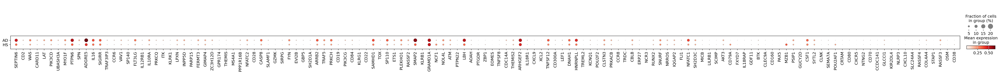

In [52]:
sc.pl.dotplot(
        adata,
        HS_ONLY,
        groupby="disease",
        #standard_scale="var",
        dendrogram=False,
    cmap="Reds",
    #save="eczema_mcps.pdf"
    )

In [53]:
1

1

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_matrixplot.py:143: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  values_df = self.obs_tidy.groupby(level=0).mean()


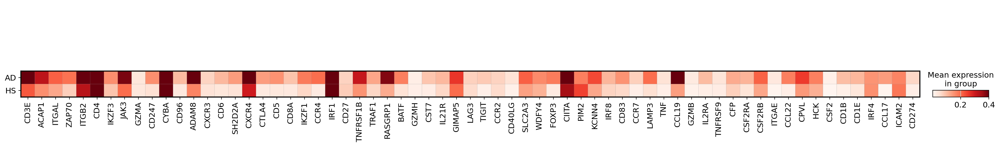

In [54]:

sc.pl.matrixplot(
        adata,
        SHARED,
        groupby="disease",
        #standard_scale="var",
        dendrogram=False,
    cmap="Reds",
    vmax=.4,
    save="shared_tdc_mcp_ORIGINAL.pdf"
    )

# Fb lesional vs nonlesional

# all

In [55]:
# KEEP = [ 'output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711',
# # 'output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049',
# # 'output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049',
#  'output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049']
ADATA=adata[adata.obs["disease"]=="HS"].copy()
adata2 = adata[adata.obs["fine_annotation"].str.startswith("F")].copy()
adata2 = adata2[adata2.obs["Site_status_binary"]!= "Day14"].copy()

#adata2 = adata2[adata2.obs["disease"]=="HS"]

# FB EXPRESSION

In [56]:
adata_fbs =sc.read_h5ad('/nfs/team361/ls34/inflow/adata_hs_spatial_5k.h5ad.norm')
adata_fbs=adata_fbs[adata_fbs.obs["disease"]=="HS"]
adata_fbs=adata_fbs[adata_fbs.obs["fine_annotation"].str.startswith("F")].copy()

/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:168: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  obs_bool.groupby(level=0).sum() / obs_bool.groupby(level=0).count()
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:178: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dot_color_df = self.obs_tidy.groupby(level=0).mean()


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_dotplot.py:747: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'norm' will be ignored
  dot_ax.scatter(x, y, **kwds)


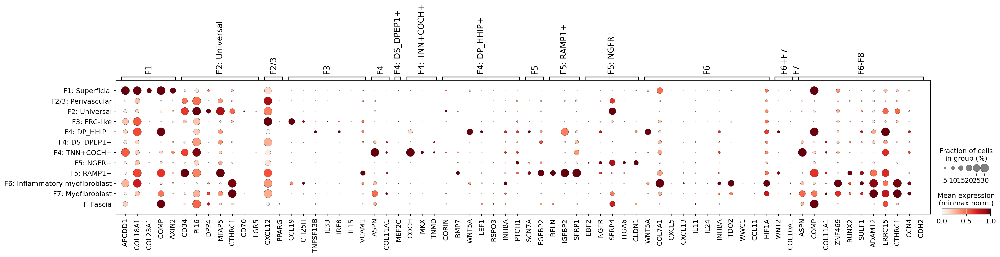

In [57]:
reynolds_short_final = {       
    "F1":[   "APCDD1",   "COL18A1",  "COL23A1",   "COL13A1",  "COMP",  
                                          "NKD2","RSPO1",  "AXIN2" , "WIF1",'SFRP2',
                                          #"HSPB3", 
                                   ],
    
                                    
                   
    "F2: Universal": ['CD34',
  'PI16',    'DPP4', 'MFAP5', 'PCOLCE2' , 'CTHRC1',   'SLPI',#  "TSPAN8",#'MATN4',
              #"CD24",  
           "CD70", "LGR5",#"KLF4"
              ],
      'F2/3': ['CXCL12', 'APOE', 'EFEMP1', #'GGT5', 
                                    "APOC1", "C7", "PLA2G2A", 'PPARG', #"CD36",
                                          #'IL1RL1', 'MARCH3', 'PCSK1', 
                                          
                                          
                                          # "FMO1", 
                                          
                                   # "PPARG", "TNFSF14"
                           "MYOC", "GDF10", # "LINC-PINT", 
                             # "POU3F3", 
                                  # "TNNT3", 
                    ],
 'F3': ['CCL19',"CD74" ,  'CH25H',  "TNFSF13B",  'IL33', "IRF8" ,#"COX4I2", 
       # "IL7",
        "IL15",
        "VCAM1", "HLA-DRA", "HLA-DRB1",# "CCL11","CCL7", "CCL2",
        
        #"ICAM1", 
        #'CX3CL1', 'ACHE', 'CCL8', 
 
           ], 
      

                           #     "EXTRA_F1": [   'COL23A1', 'CLEC2A', 'AXIN2', 'TNFRSF19', 'NTM', 'PLCB4', 'MYO10', 'RSPO1', 'COL6A5', 'AHRR', 'ESRRG', 'FREM1', 'UNC13C',
                            #       ],
               #   "F*": ['PLIN2', 'CEMIP' , 'ISG20', 'MMP1'], 
#"Palmoplantar": ["CRTAC1",# "HOXA13", "CILP2", #"F5",
#                 "SCX", "SOX5",  ], #"CDH13", "HPSE2", "CROCC", "CRTAC1", "CRLF1", "SCX", "LRFN5",

                   
                    "F4": ["ASPN", 'COL11A1',],          
 'F4: DS_DPEP1+': ['MEF2C', 
  'DPEP1',
  "MYL4", 
  #'PPP1R14A',
 # 'POSTN',
],
 'F4: TNN+COCH+': [
     #'PTGDS',
  #'OGN',
  'TNN',
  'COCH',
  'CRABP1',
  'COL24A1',"RSPO4","SLITRK6",# "CCK", 
     'NRG3', 'MKX', 'TNMD', # 'SCX'
          ],
    "F4: DP_HHIP+": ["CORIN", 
        #"INHBA", 
         "BMP7", "WNT5A", 'LEF1',
        #"SOX18", #"BAMBI", 
        "HHIP", #"RSPO2", 
        "RSPO3", "INHBA",#"ALPL",
      #  "DIO2", 
        "PTCH1", #"COL23A1", #'SOX2', 
       # 'PI15', "S100B",
           ],
        "F5": [  "SCN7A" ,"FMO2",   "FGFBP2","OLFML2A","PEAR1", # "PDGFRB", #"TAC1" 
              ],
         
                      "F5: RAMP1+": ["RAMP1", "RELN", 'PLEKHA6',  "IGFBP2", 'SFRP1', #"COL26A1", #"TAC1"
                                   ], #"CPE", "PTN", "IGF1", 

 'F5: NGFR+': [  'EBF2', "NGFR",  'SFRP4',# "TENM2", #"TM4SF1", "ANGPTL7",  
               "ITGA6", "CDH19",  "CLDN1" ,#"FOXS1", #"SOX17",
                 #"CAVIN2", "SFRP5", #"TNNC1"
                
                     ],
 
    "F6": [
            "WNT5A",
        "COL7A1",
        "CXCL8",
        "CXCL5",
         "CXCL13",
        "IL11",
        "IL24",
        "MMP1",
        "MMP3",
        "IL7R",
        "INHBA",
        #"CSF3",
        "TDO2",
        "WWC1",
        "CHI3L1",
        "CCL5",
        "CCL11",
        "FAM167A",
        "HIF1A"
    ],
    "F6+F7": [
        "WNT2",
        "COL10A1",
        "LAMP5"
    ],
    "F7": [
        "NRG1",
        "OGN"
    ],
    "F6-F8": [
        "ACTA2",
        "TAGLN",
        "ASPN",
        "COMP",
        "COL11A1",
        "KIF26B",
        "ZNF469",
        "RUNX2",
        "SULF1",
        "ADAM12",
        "ADAM19",
        "COL8A1",
        "LRRC15",
        "CREB3L1",
        "CTHRC1",
        "CCN4",
        "FABP5",
        "CDH2"
    ],
 
 
}
def remove_markers(LIST):
    try: 
        LIST = {key: [gene for gene in genes if gene in adata_fbs.var_names] 
                           for key, genes in LIST.items()}
    except: 
        LIST =[gene for gene in LIST if gene in adata_fbs.var_names]
    return LIST

adata_fbs=sc.read_h5ad('/nfs/team361/ls34/inflow/adata_hs_spatial_5k_fbsonly.h5ad.norm')
sc.pl.dotplot(
    adata_fbs,
    remove_markers(reynolds_short_final),
    groupby="fine_annotation",
    standard_scale="var",
    dendrogram=False,
    vmax=1,
                               colorbar_title="Mean expression\n(minmax norm.)",
    dot_max=0.3, # typically reduce to 0,3 to account for lower sensitivity with xenium
    #categories_order = ["Merkel cell", "ILC1", "ILC3", "ILC2"],
                                  save="fb+makrer_dotplot.pdf"

) 


In [58]:
list(adata_fbs[adata_fbs.obs["fine_annotation"].str.startswith("F")].obs["fine_annotation"].unique())

['F2/3: Perivascular',
 'F2: Universal',
 'F4: TNN+COCH+',
 'F3: FRC-like',
 'F7: Myofibroblast',
 'F1: Superficial',
 'F5: NGFR+',
 'F6: Inflammatory myofibroblast',
 'F4: DS_DPEP1+',
 'F_Fascia',
 'F5: RAMP1+',
 'F4: DP_HHIP+']

# tunnels vs non-tunnels

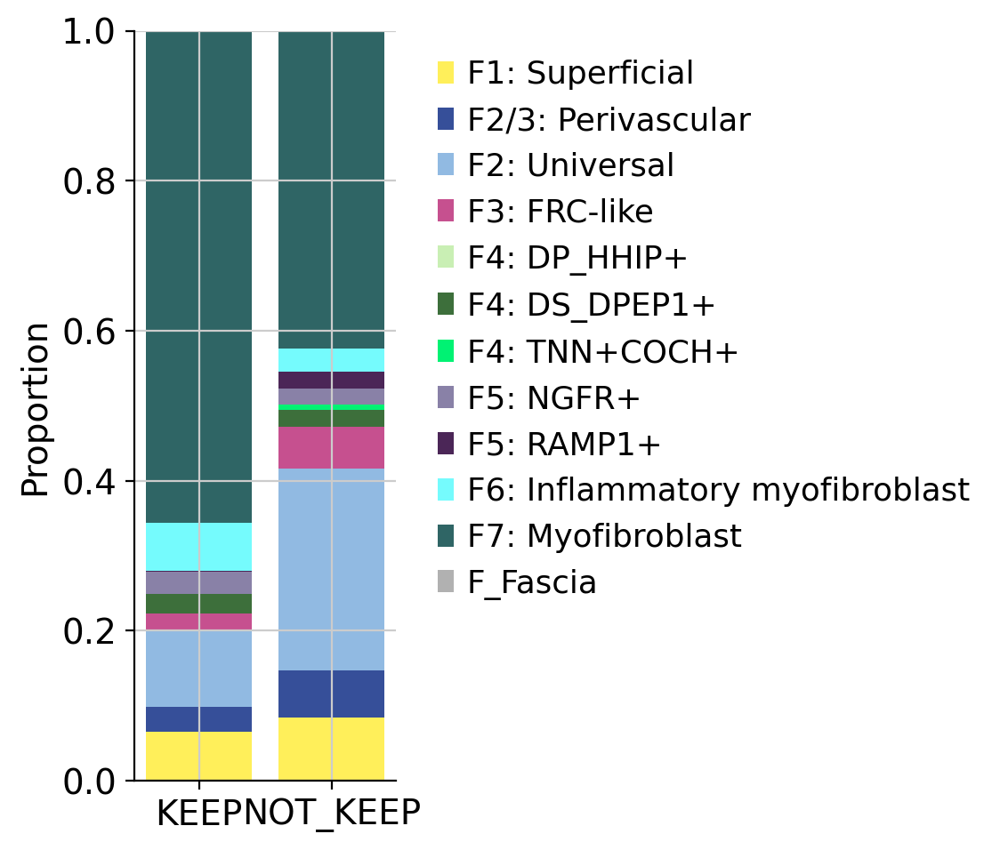

In [59]:
KEEP = [ 'output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711',
# 'output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049',
# 'output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049',
 'output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049']
ADATA=adata[adata.obs["sample_id"].isin(KEEP)].copy()
adata2 = adata[adata.obs["fine_annotation"].str.startswith("F")].copy()
adata2 = adata2[adata2.obs["disease"]=="HS"]
adata2 = adata2[adata2.obs["Site_status_binary"]=="Lesional"]



KEEP = [
    'output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711',
    'output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049'
]

# ----------------------------------
# 1. Build grouping variable
# ----------------------------------
df = adata2.obs[['sample_id', 'fine_annotation']].copy()

df['group'] = np.where(
    df['sample_id'].isin(KEEP),
    'KEEP',
    'NOT_KEEP'
)

# ----------------------------------
# 2. Count cells
# ----------------------------------
counts = (
    df
    .value_counts(['group', 'fine_annotation'])
    .rename('count')
    .reset_index()
)

# ----------------------------------
# 3. Convert to proportions
# ----------------------------------
counts['proportion'] = (
    counts
    .groupby('group')['count']
    .transform(lambda x: x / x.sum())
)

# ----------------------------------
# 4. Pivot for stacked bar plotting
# ----------------------------------
pivot = (
    counts
    .pivot(index='group', columns='fine_annotation', values='proportion')
    .fillna(0)
)

# ----------------------------------
# 5. Plot
# ----------------------------------
fig, ax = plt.subplots(figsize=(6, 5))

bottom = np.zeros(len(pivot))

for celltype in pivot.columns:
    values = pivot[celltype].values
    ax.bar(
        pivot.index,
        values,
        bottom=bottom,
        label=celltype,
        color=colors.get(celltype, "#cccccc")  # fallback = grey
    )
    bottom += values

# ----------------------------------
# 6. Aesthetics
# ----------------------------------
ax.set_ylabel("Proportion")
ax.set_xlabel("")
ax.set_ylim(0, 1)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    frameon=False
)

plt.tight_layout()
plt.show()






In [60]:
KEEP = [ 'output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711',
# 'output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049',
# 'output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049',
 'output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049']
ADATA=adata[adata.obs["sample_id"].isin(KEEP)].copy()
adata2 = adata[adata.obs["fine_annotation"].str.startswith("F")]
adata2 = adata2[adata2.obs["Site_status_binary"]!= "Day14"].copy()
adata2.obs["Site_status_binary_disease"]=adata2.obs["disease"].astype(str) + "_" + adata2.obs["Site_status_binary"].astype(str) 
#adata2 = adata2[adata2.obs["disease"]=="HS"]

/tmp/ipykernel_3867790/2412932953.py:96: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


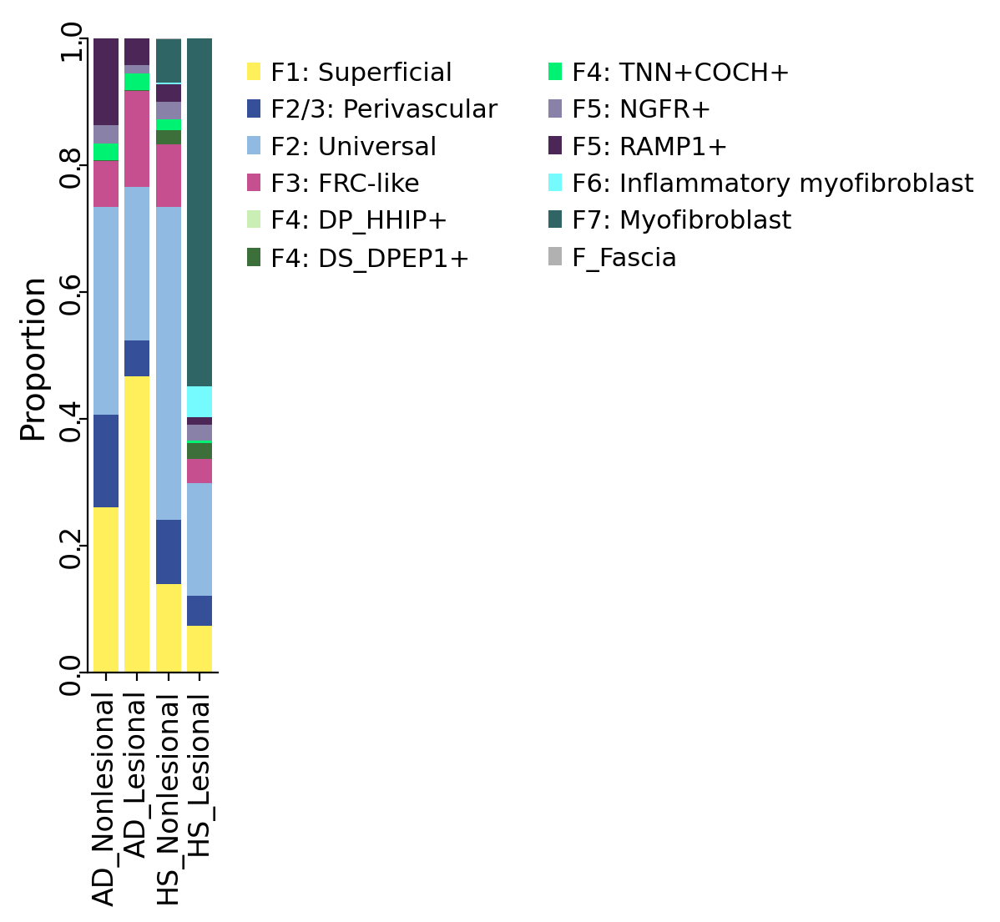

HS_Lesional: 4.89%
HS_Nonlesional: 0.24%
AD_Lesional: 0.00%


In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------------
# 1. Extract relevant columns
# ----------------------------------
df = adata2.obs[['Site_status_binary_disease', 'fine_annotation']].copy()
df = df.dropna(subset=['Site_status_binary_disease', 'fine_annotation'])

# ----------------------------------
# 2. Count cells per group
# ----------------------------------
counts = (
    df
    .value_counts(['Site_status_binary_disease', 'fine_annotation'])
    .rename('count')
    .reset_index()
)

# ----------------------------------
# 3. Convert to proportions per group
# ----------------------------------
counts['proportion'] = (
    counts
    .groupby('Site_status_binary_disease')['count']
    .transform(lambda x: x / x.sum())
)

# ----------------------------------
# 4. Pivot for stacked bars
# ----------------------------------
pivot = (
    counts
    .pivot(
        index='Site_status_binary_disease',
        columns='fine_annotation',
        values='proportion'
    )
    .fillna(0)
)

# ---- FORCE X-AXIS ORDER ----
desired_order = [
    "AD_Nonlesional",
    "AD_Lesional",
    "HS_Nonlesional",
    "HS_Lesional",
]

pivot = pivot.reindex(desired_order)

# ----------------------------------
# 5. Plot
# ----------------------------------
fig, ax = plt.subplots(figsize=(1, 5))
ax.grid(False)

bottom = np.zeros(len(pivot))

for celltype in pivot.columns:
    values = pivot[celltype].values
    ax.bar(
        pivot.index,
        values,
        bottom=bottom,
        label=celltype,
        color=colors.get(celltype, "#cccccc")
    )
    bottom += values

# ----------------------------------
# 6. Aesthetics
# ----------------------------------
ax.set_ylabel("Proportion", fontsize=14)
ax.set_xlabel("")
ax.set_ylim(0, 1)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.tick_params(axis='x', labelsize=12)
ax.tick_params(axis='y', labelsize=12)

plt.setp(ax.get_xticklabels(), rotation=90, ha="center", va="top")
plt.setp(ax.get_yticklabels(), rotation=90, ha="center", va="center")

ax.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
    frameon=False,
    fontsize=11,
    ncols=2
)

plt.tight_layout()

fig.savefig(
    "figures/lesional_vs_nl_fbs_w_AD.pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


target = "F6: Inflammatory myofibroblast"
groups = ["HS_Lesional", "HS_Nonlesional", "AD_Lesional"]

for grp in groups:
    pct = pivot.loc[grp, target] * 100 if target in pivot.columns else 0
    print(f"{grp}: {pct:.2f}%")



In [62]:
target = "F6: Inflammatory myofibroblast"
groups = ["HS_Lesional", "HS_Nonlesional", "AD_Lesional"]

for grp in groups:
    n_target = ((df["Site_status_binary_disease"] == grp)
                & (df["fine_annotation"] == target)).sum()
    n_total  = (df["Site_status_binary_disease"] == grp).sum()
    pct = 100 * n_target / n_total if n_total else 0
    print(f"{grp}: {n_target} / {n_total} = {pct:.2f}%")

HS_Lesional: 2078 / 42476 = 4.89%
HS_Nonlesional: 32 / 13554 = 0.24%
AD_Lesional: 0 / 12879 = 0.00%


# F6 analysis

In [63]:

# colors2 = {
#     "DPYD+PRDM1+": "#40E0D0",  # turquoise
#     "COLhi": "#FF9F00",       # pastel pink
#     "TWIST2+": "#E41A1C",     # red
#     "TWIST2+MMP9+": "#FF66CC",       # neon green
#     "IL11+": "#377EB8",       # blue
#     "NA": "#D3D3D3",          # light grey
# }
colors2 = {
    "DPYD+PRDM1+": "#40E0D0",  # turquoise
    "COLhi": "#FF9F00",       # pastel pink
    "TWIST2+": "#E41A1C",     # red
    "TWIST2+MMP9+": "#FF66CC",       # neon green
    "IL11+": "#377EB8",       # blue
    "NA": "#D3D3D3",          # light grey
}
colors2 = {
    "DPYD+PRDM1+": "#40E0D0",  # turquoise
    "COLhi": "#5FAF3A",       # pastel pink
    "TWIST2+": "#E41A1C",     # red
    "TWIST2+MMP9+": "#FF66CC",       # neon green
    "IL11+": "#377EB8",       # blue
    "NA": "#D3D3D3",          # light grey
}



In [64]:
import pickle
from pathlib import Path

out = Path("./f6_leiden_new.pkl")  # current working directory
with open(out, "rb") as f:
    test = pickle.load(f)


adata.obs["f6"]=adata.obs.index.map(test)
# these labels come from F6 notebook
adata.obs["f6"].value_counts()
adata=adata.copy()
import gc
gc.collect()


8529

In [65]:
adata.obs.f6.value_counts()

f6
TWIST2+         883
COLhi           472
TWIST2+MMP9+    322
IL11+           220
DPYD+PRDM1+     213
Name: count, dtype: int64

output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


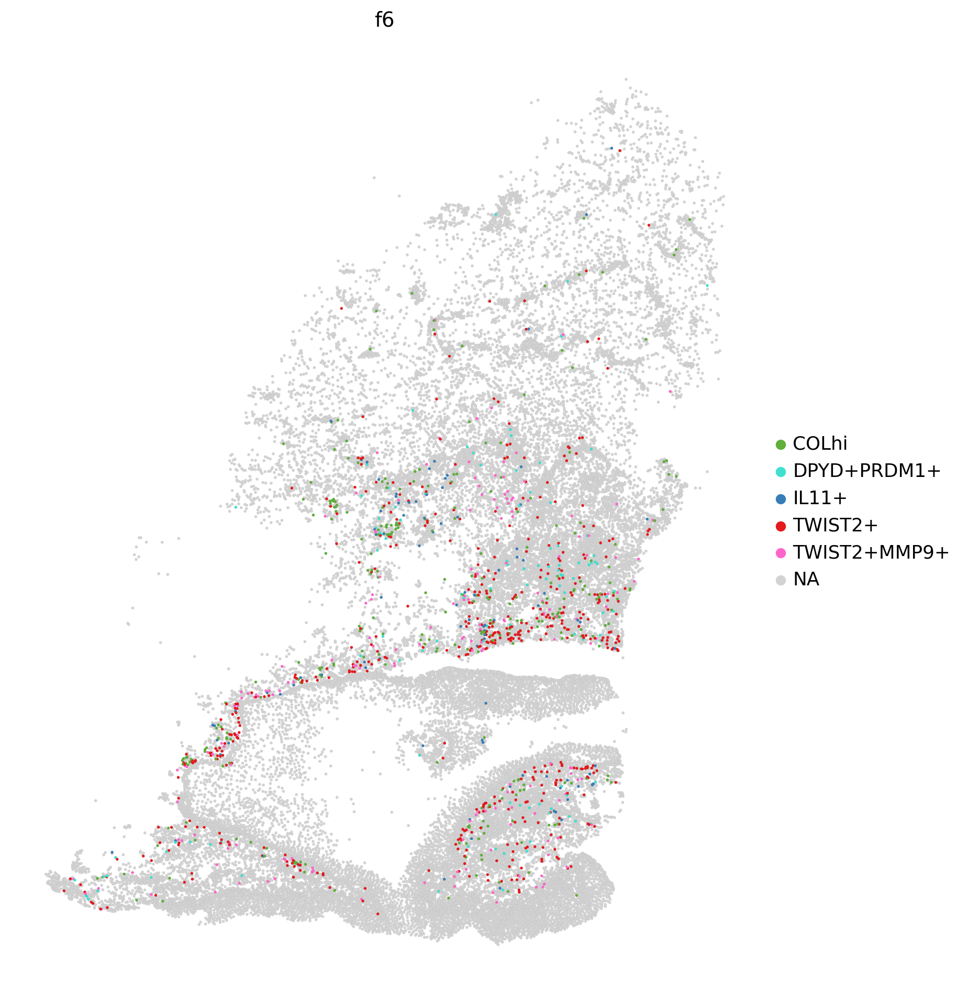

output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


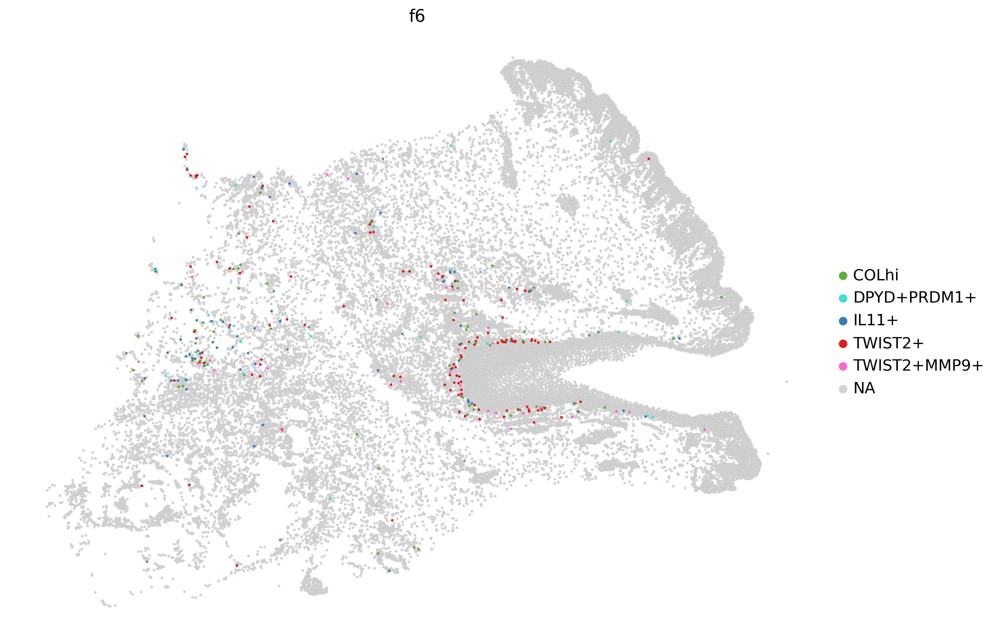

output-XETG00155__0032957__AX37-SKI-0-FO-2-S3-A2__20241217__145711


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


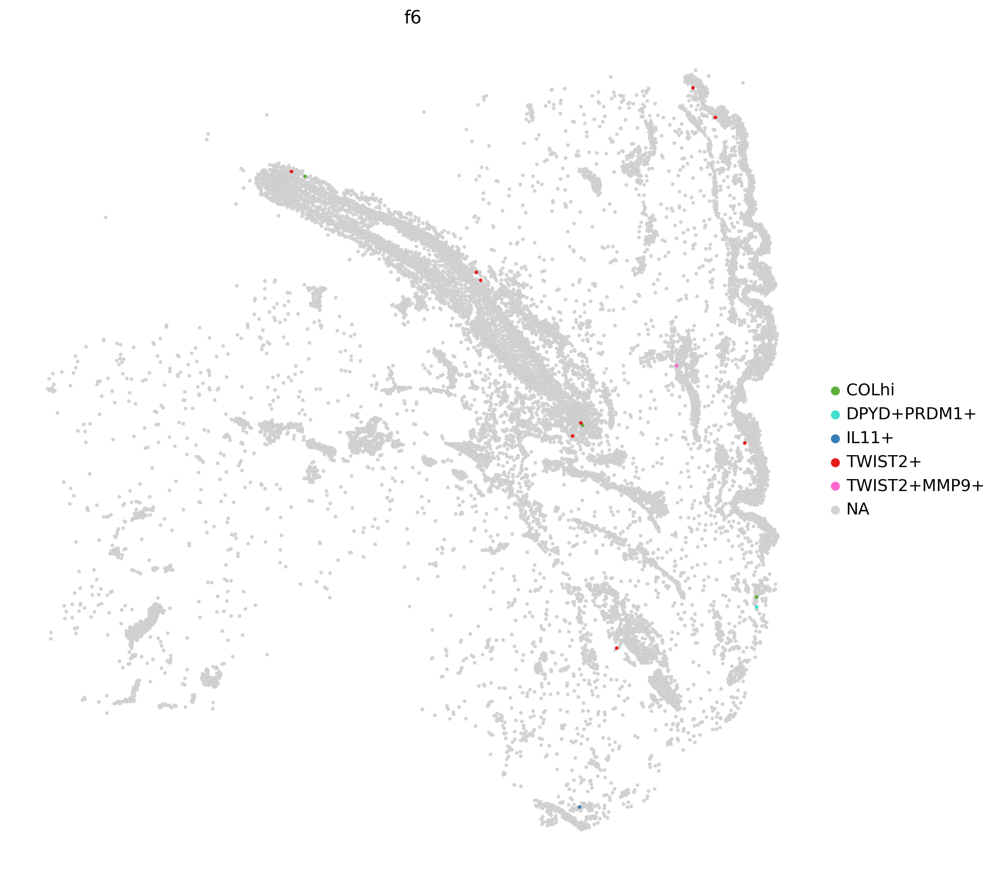

output-XETG00272__0021042__AX30-SKI-0-FO-2-S3__20240815__114049


/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/anndata/_core/anndata.py:1146: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c
/software/cellgen/team298/ls34/vqgraph/lib/python3.10/site-packages/scanpy/plotting/_tools/scatterplots.py:1234: FutureWarning: The default value of 'ignore' for the `na_action` parameter in pandas.Categorical.map is deprecated and will be changed to 'None' in a future version. Please set na_action to the desired value to avoid seeing this warning
  color_vector = pd.Categorical(values.map(color_map))


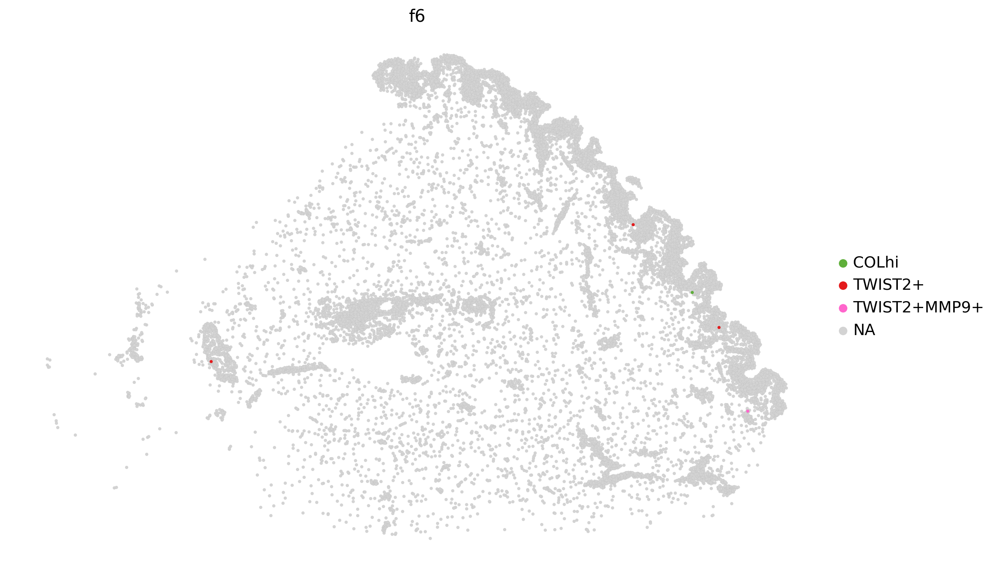

In [66]:
KEEP = [ 'output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711',
# 'output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049',
# 'output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049',
 'output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049',
        'output-XETG00155__0032957__AX37-SKI-0-FO-2-S3-A2__20241217__145711',
         'output-XETG00272__0021042__AX30-SKI-0-FO-2-S3__20240815__114049',


       ]

for slice_id in KEEP:
    print(slice_id)
    adata_i=adata[adata.obs['sample_id'] == slice_id]
    sc.pl.spatial(
        adata_i, #[adata_i.obs["fine_annotation"].str.startswith("KC")],
        color=['f6'],
        spot_size=18.0,
        wspace=0.5,
        colorbar_loc='bottom',
        palette=colors2,
        linewidth=0.01,
        edgecolor='black',
        save=f"f6_location_{slice_id}.pdf"
                          #  save="signalling_spatial.pdf"
    )

In [67]:
adata2=adata[adata.obs["sample_id"].isin( [ 'output-XETG00155__0032957__AX38-SKI-0-FO-1-S3-B1__20241217__145711',
# 'output-XETG00272__0021042__AX29-SKI-0-FO-1-S4__20240815__114049',
# 'output-XETG00272__0021042__AX29-SKI-0-FO-2-S4__20240815__114049',
 'output-XETG00272__0021042__AX30-SKI-0-FO-1-S3__20240815__114049']

)]

In [68]:
adata2.obs['f6'] = adata2.obs['f6'].astype('category')
adata2=adata2.copy()
import gc
gc.collect()

/tmp/ipykernel_3867790/4186220222.py:1: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata2.obs['f6'] = adata2.obs['f6'].astype('category')


16484

In [69]:
mode = "L"
sq.gr.ripley(adata2, cluster_key="f6", mode=mode)


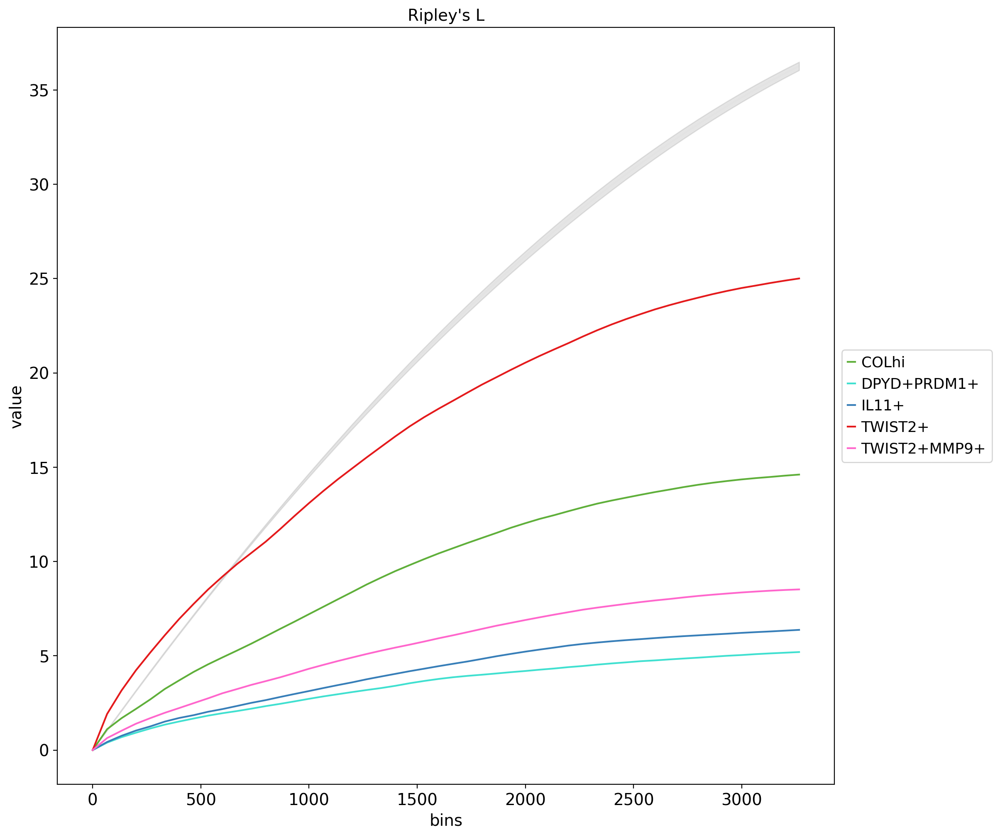

In [70]:
from matplotlib.colors import ListedColormap

colors2 = {
    "DPYD+PRDM1+": "#40E0D0",  # turquoise
    "COLhi": "#5FAF3A",        # green
    "TWIST2+": "#E41A1C",      # red
    "TWIST2+MMP9+": "#FF66CC", # pink
    "IL11+": "#377EB8",        # blue
    "NA": "#D3D3D3",           # light grey
}

# Get the category order from adata
categories = adata2.obs["f6"].cat.categories

# Map colors to categories in the correct order
colors_list = [colors2.get(cat, "#D3D3D3") for cat in categories]

# Create ListedColormap
palette = ListedColormap(colors_list)

# Plot
fig, ax = plt.subplots()
sq.pl.ripley(adata2, cluster_key="f6", mode=mode,
             palette=palette,
             save="ripleys.pdf",
             ax=ax)
ax.grid(False)
plt.show()

In [71]:
mode = "L"
sq.gr.ripley(adata2, cluster_key="f6", mode=mode, max_dist=500)


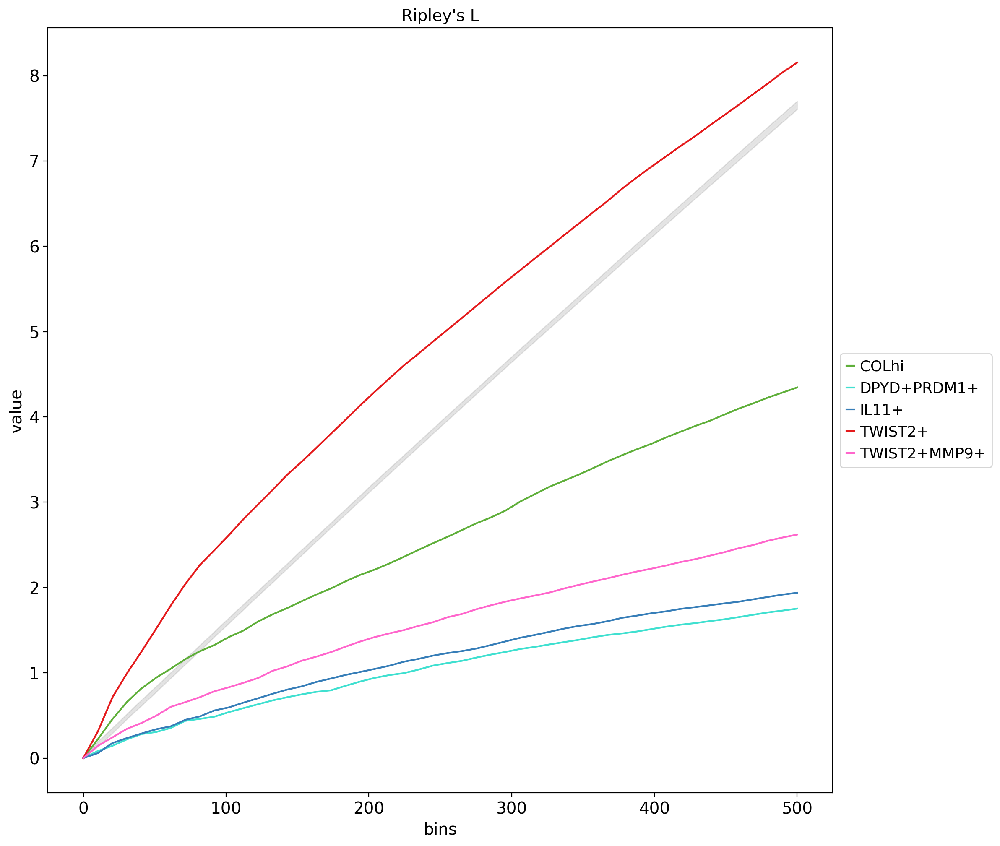

In [72]:
fig, ax = plt.subplots()

sq.pl.ripley(adata2, cluster_key="f6", mode=mode,
             palette=palette,
             save="maxdist_ripleys.pdf",
             ax=ax)

ax.grid(False)
plt.show()

In [73]:
stop

NameError: name 'stop' is not defined